# Optimisation de la sélection des caractéristiques pour la détection d'intrusions réseau à l'aide du Binary Particle Swarm Optimization et du Random Forest

**Problématique** : Les systèmes de détection d'intrusions réseau (NIDS) doivent traiter un volume massif de caractéristiques par flux, dont beaucoup sont redondantes ou peu informatives. Cette dimensionalité élevée augmente le coût de calcul et peut dégrader la généralisation des classifieurs.

**Objectif** : Appliquer le Binary PSO (BPSO) pour sélectionner un sous-ensemble de caractéristiques du dataset CIC-IDS2017, puis évaluer un Random Forest entraîné sur ce sous-ensemble par rapport à un Random Forest utilisant toutes les caractéristiques.

**Hypothèse de recherche** : Le BPSO peut réduire significativement le nombre de caractéristiques (réduction attendue > 50 %) tout en maintenant, voire en améliorant, le F1-score de la classe ATTACK sur un jeu de test indépendant.

# Installation des bibliothèques nécessaires (Colab dispose déjà de la plupart)
!pip install -q datasets scikit-learn matplotlib seaborn pandas numpy

In [2]:
import os, random, time, warnings, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             classification_report, confusion_matrix,
                             roc_curve, precision_recall_curve)

# Reproductibilité
SEED = 2026
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Configuration d'affichage
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

# Style scientifique
sns.set_theme(style='whitegrid', palette='deep', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

print('Environnement configuré. Seed =', SEED)
print('Version pandas :', pd.__version__)
print('Version scikit-learn :', __import__('sklearn').__version__)

Environnement configuré. Seed = 2026
Version pandas : 2.2.3
Version scikit-learn : 1.6.1


In [3]:
DATASET_NAME = "muzom/CIC-IDS2017"
ALTERNATIVE_NAME = "c01dsnap/CIC-IDS2017"

def charger_dataset(nom):
    ds = load_dataset(nom, split="train")
    return ds.to_pandas()

try:
    print(f"Tentative de chargement : {DATASET_NAME}")
    df = charger_dataset(DATASET_NAME)
    print(f"Dataset chargé avec succès depuis {DATASET_NAME}")
except Exception as e:
    print(f"Échec du chargement de {DATASET_NAME} : {e}")
    print(f"Tentative avec la source alternative : {ALTERNATIVE_NAME}")
    try:
        df = charger_dataset(ALTERNATIVE_NAME)
        print(f"Dataset chargé depuis {ALTERNATIVE_NAME}")
    except Exception as e2:
        raise RuntimeError(
            "Impossible de charger le dataset CIC-IDS2017 depuis les sources Hugging Face. "
            "Vérifiez votre connexion ou utilisez une autre source documentée."
        ) from e2

print('Dimensions brutes :', df.shape)

Tentative de chargement : muzom/CIC-IDS2017


README.md:   0%|          | 0.00/771 [00:00<?, ?B/s]

Friday-WorkingHours-Afternoon-DDos.pcap_(…): reconstructing file:   0%|          |  0.00B / 77.1MB            

Friday-WorkingHours-Afternoon-DDos.pcap_(…): downloading bytes:           |  0.00B            

Friday-WorkingHours-Afternoon-PortScan.p(…): reconstructing file:   0%|          |  0.00B / 76.9MB            

...

Tuesday-WorkingHours.pcap_ISCX.csv: downloading bytes:           |  0.00B            

Wednesday-workingHours.pcap_ISCX.csv: reconstructing file:   0%|          |  0.00B /  225MB            

Wednesday-workingHours.pcap_ISCX.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2830743 [00:00<?, ? examples/s]

Dataset chargé avec succès depuis muzom/CIC-IDS2017
Dimensions brutes : (2830743, 79)


In [4]:
print('Aperçu des 5 premières lignes :')
display(df.head())

print('\nTypes de données :')
print(df.dtypes.value_counts())

print('\nNombre de colonnes :', df.shape[1])
print('Nombre de lignes :', df.shape[0])

print('\nMémoire utilisée par le DataFrame :')
print(f'{df.memory_usage(deep=True).sum() / 1024**2:.2f} Mo')

print('\nColonnes :', list(df.columns))

Aperçu des 5 premières lignes :


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0000,0.0000,0,0,0.0000,0.0000,4000000.0000,666666.6667,3.0000,0.0000,3,3,3,3.0000,0.0000,3,3,0,0.0000,0.0000,0,0,0,0,0,0,40,0,666666.6667,0.0000,6,6,6.0000,0.0000,0.0000,0,0,0,0,1,0,0,0,0,9.0000,6.0000,0.0000,40,0,0,0,0,0,0,2,12,0,0,33,-1,1,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,110091.7431,18348.6238,109.0000,0.0000,109,109,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,9174.3119,9174.3119,6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,230769.2308,38461.5385,52.0000,0.0000,52,52,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,19230.7692,19230.7692,6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,352941.1765,58823.5294,34.0000,0.0000,34,34,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,29411.7647,29411.7647,6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,31,329,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0000,0.0000,0,0,0.0000,0.0000,4000000.0000,666666.6667,3.0000,0.0000,3,3,3,3.0000,0.0000,3,3,0,0.0000,0.0000,0,0,0,0,0,0,40,0,666666.6667,0.0000,6,6,6.0000,0.0000,0.0000,0,0,0,0,1,0,0,0,0,9.0000,6.0000,0.0000,40,0,0,0,0,0,0,2,12,0,0,32,-1,1,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN



Types de données :
int64      54
float64    24
object      1
Name: count, dtype: int64

Nombre de colonnes : 79
Nombre de lignes : 2830743

Mémoire utilisée par le DataFrame :
1833.87 Mo

Colonnes : [' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length',

In [7]:
# Valeurs manquantes
nan_counts = df.isna().sum()
print('Colonnes avec valeurs manquantes :')
print(nan_counts[nan_counts > 0] if nan_counts.sum() > 0 else 'Aucune valeur manquante détectée.')

# Doublons
n_doublons = df.duplicated().sum()
print(f'\nNombre de lignes dupliquées : {n_doublons}')

# Valeurs infinies (uniquement sur les colonnes numériques)
num_cols = df.select_dtypes(include=[np.number]).columns
inf_counts = np.isinf(df[num_cols]).sum()
print('\nColonnes avec valeurs infinies :')
print(inf_counts[inf_counts > 0] if inf_counts.sum() > 0 else 'Aucune valeur infinie détectée.')

# Vérification des types
print('\nColonnes non numériques (hors Label) :')
non_num = df.select_dtypes(exclude=[np.number]).columns.tolist()
print([c for c in non_num if c != 'Label'] if len(non_num) > 1 else 'Aucune.')

Colonnes avec valeurs manquantes :
Flow Bytes/s    1358
dtype: int64

Nombre de lignes dupliquées : 308381

Colonnes avec valeurs infinies :
Flow Bytes/s       1509
 Flow Packets/s    2867
dtype: int64

Colonnes non numériques (hors Label) :
Aucune.


In [ ]:


def _detecter_colonne_label(df):
    # 1) Chercher BENIGN dans les valeurs (le plus fiable)
    for c in df.columns:
        try:
            vals = df[c].astype(str).str.strip().str.upper().unique()
            if any('BENIGN' in v for v in vals):
                return c, 'contains_BENIGN'
        except Exception:
            pass
    # 2) Chercher un nom contenant 'label'
    candidats = [c for c in df.columns
                 if 'label' in str(c).strip().lower()]
    if candidats:
        return candidats[0], 'keyword_match'
    # 3) Dernière colonne non numérique
    objs = [c for c in df.columns
            if str(df[c].dtype) in ('object', 'string', 'category')]
    if objs:
        return objs[-1], 'last_object_column'
    raise RuntimeError("Aucune colonne label détectée. Inspectez df.columns.")

if 'LABEL_COL' not in globals():
    LABEL_COL, raison = _detecter_colonne_label(df)
    print(f'ℹ️  LABEL_COL détecté automatiquement : {repr(LABEL_COL)}  ({raison})')
else:
    print(f'ℹ️  LABEL_COL déjà défini : {repr(LABEL_COL)}')

# Redéfinir num_cols si nécessaire (exclut toujours LABEL_COL)
num_cols = [c for c in df.select_dtypes(include=[np.number]).columns
            if c != LABEL_COL]

print(f'ℹ️  Colonnes numériques (hors label) : {len(num_cols)}')


print(f'\nDistribution originale de la variable {repr(LABEL_COL)} :')
label_counts = df[LABEL_COL].value_counts()
print(label_counts)

print(f'\nNombre de classes distinctes : {df[LABEL_COL].nunique()}')

fig, ax = plt.subplots(figsize=(10, 5))
label_counts.plot(kind='barh', ax=ax, color=sns.color_palette('deep'))
ax.set_title(f'Distribution originale des classes ({LABEL_COL})')
ax.set_xlabel('Nombre de flux')
ax.set_ylabel('Classe')
for i, v in enumerate(label_counts.values):
    ax.text(v + label_counts.max() * 0.01, i, f'{v:,}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('fig01_distribution_originale.png', dpi=300)
plt.show()



ℹ️  LABEL_COL détecté automatiquement : ' Label'  (contains_BENIGN)


In [2]:
import numpy as np, pandas as pd, time, random
from datasets import load_dataset
from sklearn.model_selection import train_test_split

# (1) Vérifier que df existe, sinon recharger
if 'df' not in globals():
    print('ℹ️  df absent → rechargement du dataset...')
    for nom in ["muzom/CIC-IDS2017", "c01dsnap/CIC-IDS2017"]:
        try:
            df = load_dataset(nom, split="train").to_pandas()
            print(f'✅ Chargé depuis {nom} | shape {df.shape}')
            break
        except Exception as e:
            print(f'   échec {nom} : {e}')
    else:
        raise RuntimeError("Impossible de recharger le dataset.")

# (2) Vérifier que LABEL_COL existe, sinon le détecter
if 'LABEL_COL' not in globals():
    print('ℹ️  LABEL_COL absent → détection...')
    def _detecter(df):
        for c in df.columns:
            try:
                vals = df[c].astype(str).str.strip().str.upper().unique()
                if any('BENIGN' in v for v in vals):
                    return c
            except Exception:
                pass
        for c in df.columns:
            if 'label' in str(c).strip().lower():
                return c
        objs = [c for c in df.columns
                if str(df[c].dtype) in ('object', 'string', 'category')]
        return objs[-1] if objs else None
    LABEL_COL = _detecter(df)
    print(f'✅ LABEL_COL = {repr(LABEL_COL)}')

# (3) Redéfinir num_cols (exclut toujours LABEL_COL)
num_cols = [c for c in df.select_dtypes(include=[np.number]).columns
            if c != LABEL_COL]


print(f'\nLabels avant transformation (colonne {repr(LABEL_COL)}) :')
print(sorted(df[LABEL_COL].astype(str).str.strip().unique())[:30])

df['target'] = df[LABEL_COL].apply(
    lambda x: 0 if str(x).strip().upper() == 'BENIGN' else 1
)

print('\nDistribution binaire :')
print(df['target'].value_counts())
print(f'Proportion d\'attaques : {df["target"].mean():.4f}')

assert set(df['target'].unique()) == {0, 1}, "La cible doit être {0, 1}."
assert df['target'].isna().sum() == 0, "NaN dans target."
print('\n✅ Transformation binaire validée.')

ℹ️  df absent → rechargement du dataset...


✅ Chargé depuis muzom/CIC-IDS2017 | shape (2830743, 79)
ℹ️  LABEL_COL absent → détection...
✅ LABEL_COL = ' Label'

Labels avant transformation (colonne ' Label') :
['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack � Brute Force', 'Web Attack � Sql Injection', 'Web Attack � XSS']

Distribution binaire :
target
0    2273097
1     557646
Name: count, dtype: int64
Proportion d'attaques : 0.1970

✅ Transformation binaire validée.


In [3]:

import numpy as np

# --- Sécurité : reconstruire les variables si le noyau a redémarré ---
if 'df' not in globals():
    raise RuntimeError(
        "df absent — exécutez d'abord la cellule BOOTSTRAP ou la cellule 4."
    )

if 'LABEL_COL' not in globals():
    def _detecter(df):
        for c in df.columns:
            try:
                if any('BENIGN' in v for v in
                       df[c].astype(str).str.strip().str.upper().unique()):
                    return c
            except Exception:
                pass
        for c in df.columns:
            if 'label' in str(c).strip().lower():
                return c
        objs = [c for c in df.columns
                if str(df[c].dtype) in ('object', 'string', 'category')]
        return objs[-1]
    LABEL_COL = _detecter(df)
    print(f'ℹ️  LABEL_COL redétecté : {repr(LABEL_COL)}')

# --- Redéfinir num_cols en excluant toujours LABEL_COL ---
num_cols = [c for c in df.select_dtypes(include=[np.number]).columns
            if c != LABEL_COL]
print(f'Colonnes numériques à nettoyer : {len(num_cols)}')

# ============================================================
# 1) Remplacer les infinis par NaN
# ============================================================
n_inf_avant = int(np.isinf(df[num_cols]).sum().sum())
print(f'\nValeurs infinies détectées avant remplacement : {n_inf_avant:,}')

df[num_cols] = df[num_cols].replace([np.inf, -np.inf], np.nan)

# ============================================================
# 2) Supprimer les lignes contenant au moins un NaN
# ============================================================
n_avant = len(df)
n_nan_total = int(df[num_cols].isna().sum().sum())
print(f'Valeurs NaN totales avant suppression : {n_nan_total:,}')

df = df.dropna(subset=num_cols).reset_index(drop=True)
n_apres = len(df)

print(f'\nLignes avant nettoyage : {n_avant:,}')
print(f'Lignes après nettoyage : {n_apres:,}')
print(f'Lignes supprimées      : {n_avant - n_apres:,} '
      f'({100 * (n_avant - n_apres) / n_avant:.2f} %)')
print(f'Pourcentage conservé   : {100 * n_apres / n_avant:.2f} %')

# ============================================================
# 3) Vérifications finales
# ============================================================
assert df[num_cols].isna().sum().sum() == 0, "Il reste des NaN."
assert np.isfinite(df[num_cols]).all().all(), "Il reste des valeurs non finies."
assert len(df) > 0, "Le DataFrame est vide après nettoyage."
assert LABEL_COL in df.columns, f"La colonne {repr(LABEL_COL)} a disparu."

print('\n✅ Nettoyage validé.')
print(f'Dimensions finales de df : {df.shape}')

Colonnes numériques à nettoyer : 79

Valeurs infinies détectées avant remplacement : 4,376
Valeurs NaN totales avant suppression : 5,734

Lignes avant nettoyage : 2,830,743
Lignes après nettoyage : 2,827,876
Lignes supprimées      : 2,867 (0.10 %)
Pourcentage conservé   : 99.90 %

✅ Nettoyage validé.
Dimensions finales de df : (2827876, 80)


In [4]:

import numpy as np

# --- Sécurité après redémarrage du noyau ---
if 'df' not in globals():
    raise RuntimeError("df absent — exécutez la cellule 9 ou BOOTSTRAP d'abord.")
if 'LABEL_COL' not in globals():
    def _detecter(df):
        for c in df.columns:
            try:
                if any('BENIGN' in v for v in
                       df[c].astype(str).str.strip().str.upper().unique()):
                    return c
            except Exception:
                pass
        for c in df.columns:
            if 'label' in str(c).strip().lower():
                return c
        objs = [c for c in df.columns
                if str(df[c].dtype) in ('object', 'string', 'category')]
        return objs[-1]
    LABEL_COL = _detecter(df)
    print(f'ℹ️  LABEL_COL redétecté : {repr(LABEL_COL)}')

# --- Colonnes numériques hors label ---
num_cols = [c for c in df.select_dtypes(include=[np.number]).columns
            if c != LABEL_COL]

# ============================================================
# Exclusions : label + target (fuite directe)
# ============================================================
colonnes_exclues = [LABEL_COL, 'target']
if 'target' not in df.columns:
    raise RuntimeError(
        "La colonne 'target' est absente — exécutez la cellule 8 d'abord."
    )

# Audit rapide des colonnes potentiellement fuyantes
suspectes = [c for c in df.columns
             if any(k in str(c).strip().lower()
                    for k in ['id', 'ip', 'time', 'date'])]
suspectes = [c for c in suspectes if c not in colonnes_exclues]
print('Colonnes suspectes (à examiner) :',
      suspectes if suspectes else 'Aucune.')

# ============================================================
# Construction de X et y
# ============================================================
feature_cols = [c for c in df.columns
                if c not in colonnes_exclues and c in num_cols]

X = df[feature_cols].copy()
y = df['target'].copy()

print(f'\nNombre de caractéristiques retenues : {len(feature_cols)}')
print(f'X : {X.shape}  |  y : {y.shape}')
print(f'Distribution y : {y.value_counts().to_dict()}')

# ============================================================
# Vérifications
# ============================================================
assert len(feature_cols) > 0, "Aucune caractéristique retenue."
assert LABEL_COL not in feature_cols, f"{repr(LABEL_COL)} ne doit pas être dans X."
assert 'target' not in feature_cols, "'target' ne doit pas être dans X."
assert np.isfinite(X).all().all(), "X contient des valeurs non finies."
assert y.isna().sum() == 0, "y contient des NaN."
assert set(y.unique()) == {0, 1}, "y doit être binaire {0, 1}."

print('\n✅ X et y validés.')
print(f'Première caractéristique : {feature_cols[0]}')
print(f'Dernière caractéristique : {feature_cols[-1]}')

Colonnes suspectes (à examiner) : ['Idle Mean', ' Idle Std', ' Idle Max', ' Idle Min']

Nombre de caractéristiques retenues : 78
X : (2827876, 78)  |  y : (2827876,)
Distribution y : {0: 2271320, 1: 556556}

✅ X et y validés.
Première caractéristique :  Destination Port
Dernière caractéristique :  Idle Min


In [6]:
# ============================================================
# CELLULE 11 — Échantillonnage stratifié (auto-suffisante)
# ============================================================
import os, random
import numpy as np
from sklearn.model_selection import train_test_split

# --- Sécurité : SEED toujours défini ---
if 'SEED' not in globals():
    SEED = 2026
    os.environ['PYTHONHASHSEED'] = str(SEED)
    random.seed(SEED)
    np.random.seed(SEED)
    print(f'ℹ️  SEED redéfini = {SEED}')

# --- Sécurité : X et y doivent exister ---
if 'X' not in globals() or 'y' not in globals():
    raise RuntimeError("X/y absents — exécutez la cellule 10 d'abord.")

# ===== CONFIGURATION =====
TAILLE_ECHANTILLON = 300_000   # None = dataset complet
# =================================

if TAILLE_ECHANTILLON is not None and TAILLE_ECHANTILLON < len(X):
    X_sample, _, y_sample, _ = train_test_split(
        X, y,
        train_size=TAILLE_ECHANTILLON,
        stratify=y,
        random_state=SEED
    )
    print(f'Échantillon stratifié : {len(X_sample):,} / {len(X):,}')
    print(f'Proportion attaques dans l\'échantillon : {y_sample.mean():.4f}')
else:
    X_sample, y_sample = X, y
    print('Dataset complet utilisé (aucun échantillonnage).')

print(f'\nX_sample : {X_sample.shape}  |  y_sample : {y_sample.shape}')
print(f'Distribution y_sample : {y_sample.value_counts().to_dict()}')

assert len(X_sample) > 0
assert np.isfinite(X_sample).all().all()
print('\n✅ Cellule 11 terminée.')

ℹ️  SEED redéfini = 2026
Échantillon stratifié : 300,000 / 2,827,876
Proportion attaques dans l'échantillon : 0.1968

X_sample : (300000, 78)  |  y_sample : (300000,)
Distribution y_sample : {0: 240957, 1: 59043}

✅ Cellule 11 terminée.


In [7]:
# ============================================================
# CELLULE 12 — Split 70/15/15 (auto-suffisante)
# ============================================================
from sklearn.model_selection import train_test_split

if 'SEED' not in globals():
    SEED = 2026
    print(f'ℹ️  SEED redéfini = {SEED}')

if 'X_sample' not in globals() or 'y_sample' not in globals():
    raise RuntimeError("X_sample/y_sample absents — exécutez la cellule 11.")

X_train, X_temp, y_train, y_temp = train_test_split(
    X_sample, y_sample,
    test_size=0.30, stratify=y_sample, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50, stratify=y_temp, random_state=SEED
)

print('Train      :', X_train.shape, '| attaques :', f'{y_train.mean():.4f}')
print('Validation :', X_val.shape,   '| attaques :', f'{y_val.mean():.4f}')
print('Test       :', X_test.shape,  '| attaques :', f'{y_test.mean():.4f}')

assert len(X_train) + len(X_val) + len(X_test) == len(X_sample)
assert abs(y_train.mean() - y_sample.mean()) < 0.01
assert abs(y_val.mean()   - y_sample.mean()) < 0.01
assert abs(y_test.mean()  - y_sample.mean()) < 0.01
print('\n✅ Split stratifié validé.')

Train      : (210000, 78) | attaques : 0.1968
Validation : (45000, 78) | attaques : 0.1968
Test       : (45000, 78) | attaques : 0.1968

✅ Split stratifié validé.


In [8]:
import numpy as np

# --- Sécurité après redémarrage du noyau ---
if 'SEED' not in globals():
    SEED = 2026
    print(f'ℹ️  SEED redéfini = {SEED}')

required = ['X_train', 'X_val', 'X_test', 'y_train', 'y_val', 'y_test',
            'X_sample', 'y_sample']
missing = [v for v in required if v not in globals()]
if missing:
    raise RuntimeError(
        f"Variables manquantes : {missing}. "
        "Exécutez la BOOTSTRAP ou les cellules 10-11-12."
    )

# ============================================================
# 1) Aucun chevauchement d'index entre ensembles
# ============================================================
overlap_tv = len(set(X_train.index) & set(X_val.index))
overlap_tt = len(set(X_train.index) & set(X_test.index))
overlap_vt = len(set(X_val.index)   & set(X_test.index))

print('=== Chevauchement d\'index ===')
print(f'Train ∩ Val  : {overlap_tv}')
print(f'Train ∩ Test : {overlap_tt}')
print(f'Val   ∩ Test : {overlap_vt}')

assert overlap_tv == 0, "Chevauchement Train/Val détecté !"
assert overlap_tt == 0, "Chevauchement Train/Test détecté !"
assert overlap_vt == 0, "Chevauchement Val/Test détecté !"

# ============================================================
# 2) Distribution des classes similaire dans les trois ensembles
# ============================================================
print('\n=== Distribution des classes ===')
dist_df = pd.DataFrame({
    'Ensemble':  ['Train', 'Validation', 'Test', 'Référence'],
    'Taille':    [len(y_train), len(y_val), len(y_test), len(y_sample)],
    'Proportion attaques':
        [y_train.mean(), y_val.mean(), y_test.mean(), y_sample.mean()]
}).round(4)
print(dist_df.to_string(index=False))

# Tolérance : écart max < 1 point de pourcentage
for nom, yy in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]:
    ecart = abs(yy.mean() - y_sample.mean())
    assert ecart < 0.01, f"Écart de distribution trop grand dans {nom} : {ecart:.4f}"

# ============================================================
# 3) Dimensions cohérentes (même nombre de caractéristiques)
# ============================================================
n_features_train = X_train.shape[1]
n_features_val   = X_val.shape[1]
n_features_test  = X_test.shape[1]

print('\n=== Dimensions ===')
print(f'X_train : {X_train.shape}')
print(f'X_val   : {X_val.shape}')
print(f'X_test  : {X_test.shape}')

assert n_features_train == n_features_val == n_features_test, \
    "Nombre de caractéristiques différent entre ensembles !"

# ============================================================
# 4) Absence de NaN / infinis dans X
# ============================================================
print('\n=== Intégrité numérique ===')
for nom, XX in [('X_train', X_train), ('X_val', X_val), ('X_test', X_test)]:
    n_nan = int(XX.isna().sum().sum())
    n_inf = int(np.isinf(XX).sum().sum())
    print(f'{nom:8s} : NaN={n_nan}  | inf={n_inf}')
    assert n_nan == 0, f"NaN dans {nom}."
    assert n_inf == 0, f"Infinis dans {nom}."

# ============================================================
# 5) Cible binaire valide dans chaque ensemble
# ============================================================
print('\n=== Cible binaire ===')
for nom, yy in [('y_train', y_train), ('y_val', y_val), ('y_test', y_test)]:
    uniques = sorted(yy.unique())
    print(f'{nom:8s} : classes = {uniques}')
    assert set(uniques) == {0, 1}, f"{nom} doit être strictement binaire {{0,1}}."

# ============================================================
# 6) Résumé final
# ============================================================
total = len(X_train) + len(X_val) + len(X_test)
print('\n=== Résumé ===')
print(f'Total lignes          : {total:,}  (= {len(X_sample):,} attendu)')
print(f'Caractéristiques      : {n_features_train}')
print(f'Ratio Train/Val/Test  : {len(X_train)/total:.2f} / '
      f'{len(X_val)/total:.2f} / {len(X_test)/total:.2f}')

assert total == len(X_sample), "Somme des splits ≠ échantillon total."

print('\n✅ Cellule 13 terminée — partitions validées.')

=== Chevauchement d'index ===
Train ∩ Val  : 0
Train ∩ Test : 0
Val   ∩ Test : 0

=== Distribution des classes ===
  Ensemble  Taille  Proportion attaques
     Train  210000               0.1968
Validation   45000               0.1968
      Test   45000               0.1968
 Référence  300000               0.1968

=== Dimensions ===
X_train : (210000, 78)
X_val   : (45000, 78)
X_test  : (45000, 78)

=== Intégrité numérique ===
X_train  : NaN=0  | inf=0
X_val    : NaN=0  | inf=0
X_test   : NaN=0  | inf=0

=== Cible binaire ===
y_train  : classes = [np.int64(0), np.int64(1)]
y_val    : classes = [np.int64(0), np.int64(1)]
y_test   : classes = [np.int64(0), np.int64(1)]

=== Résumé ===
Total lignes          : 300,000  (= 300,000 attendu)
Caractéristiques      : 78
Ratio Train/Val/Test  : 0.70 / 0.15 / 0.15

✅ Cellule 13 terminée — partitions validées.


In [9]:

import time
import numpy as np
from sklearn.ensemble import RandomForestClassifier

# --- Sécurité après redémarrage du noyau ---
if 'SEED' not in globals():
    SEED = 2026
    print(f'ℹ️  SEED redéfini = {SEED}')

required = ['X_train', 'y_train', 'X_val', 'y_val', 'feature_cols']
missing = [v for v in required if v not in globals()]
if missing:
    raise RuntimeError(
        f"Variables manquantes : {missing}. "
        "Exécutez la BOOTSTRAP ou les cellules 10-11-12-13."
    )

# ============================================================
# Définition des hyperparamètres (réutilisés pour le modèle BPSO)
# ============================================================
RF_PARAMS = dict(
    n_estimators=100,
    max_depth=None,
    random_state=SEED,
    n_jobs=-1,
    class_weight='balanced_subsample'
)

# ============================================================
# Entraînement sur toutes les caractéristiques
# ============================================================
print('=== Entraînement du modèle de référence ===')
print(f'Caractéristiques utilisées : {X_train.shape[1]}')
print(f'Lignes d\'entraînement     : {len(X_train):,}')
print(f'Hyperparamètres           : n_estimators=100, max_depth=None, '
      f'class_weight=balanced_subsample')

rf_full = RandomForestClassifier(**RF_PARAMS)

t0 = time.time()
rf_full.fit(X_train, y_train)
train_time_full = time.time() - t0

print(f'\nTemps d\'entraînement : {train_time_full:.2f} s')
print(f'Nombre d\'arbres      : {len(rf_full.estimators_)}')
print(f'Profondeur moyenne   : '
      f'{np.mean([t.get_depth() for t in rf_full.estimators_]):.1f}')

# ============================================================
# Vérifications
# ============================================================
assert rf_full.n_features_in_ == X_train.shape[1]
assert train_time_full > 0

print('\n✅ Modèle de référence entraîné.')
print(f'Nombre de features vues par le modèle : {rf_full.n_features_in_}')
print(f'Temps d\'entraînement                  : {train_time_full:.2f} s')

=== Entraînement du modèle de référence ===
Caractéristiques utilisées : 78
Lignes d'entraînement     : 210,000
Hyperparamètres           : n_estimators=100, max_depth=None, class_weight=balanced_subsample

Temps d'entraînement : 73.14 s
Nombre d'arbres      : 100
Profondeur moyenne   : 29.7

✅ Modèle de référence entraîné.
Nombre de features vues par le modèle : 78
Temps d'entraînement                  : 73.14 s


In [10]:

import time
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

# --- Sécurité après redémarrage du noyau ---
required = ['rf_full', 'X_test', 'y_test', 'train_time_full']
missing = [v for v in required if v not in globals()]
if missing:
    raise RuntimeError(
        f"Variables manquantes : {missing}. "
        "Exécutez les cellules 12 et 14 d'abord."
    )

# ============================================================
# Fonction utilitaire de calcul des métriques (réutilisée en 30)
# ============================================================
def calculer_metriques(y_true, y_pred, y_proba):
    """Calcule les 6 métriques clés pour un modèle binaire."""
    return {
        'accuracy':          accuracy_score(y_true, y_pred),
        'precision':         precision_score(y_true, y_pred, zero_division=0),
        'recall':            recall_score(y_true, y_pred, zero_division=0),
        'f1':                f1_score(y_true, y_pred, zero_division=0),
        'roc_auc':           roc_auc_score(y_true, y_proba),
        'average_precision': average_precision_score(y_true, y_proba),
    }

# ============================================================
# Prédiction sur le jeu de test (isolé)
# ============================================================
print('=== Évaluation du modèle de référence sur le test ===')
print(f'Lignes de test : {len(X_test):,}')

t0 = time.time()
y_pred_full = rf_full.predict(X_test)
pred_time_full = time.time() - t0

# Probabilités de la classe ATTACK (colonne 1)
y_proba_full = rf_full.predict_proba(X_test)[:, 1]

# ============================================================
# Calcul des métriques
# ============================================================
metrics_full = calculer_metriques(y_test, y_pred_full, y_proba_full)

# ============================================================
# Affichage structuré
# ============================================================
print('\n=== Métriques (test) ===')
print(f'{"Accuracy":22s} : {metrics_full["accuracy"]:.4f}')
print(f'{"Precision":22s} : {metrics_full["precision"]:.4f}')
print(f'{"Recall (ATTACK)":22s} : {metrics_full["recall"]:.4f}')
print(f'{"F1-score":22s} : {metrics_full["f1"]:.4f}')
print(f'{"ROC-AUC":22s} : {metrics_full["roc_auc"]:.4f}')
print(f'{"Average Precision":22s} : {metrics_full["average_precision"]:.4f}')

print(f'\n=== Temps ===')
print(f'{"Entraînement":22s} : {train_time_full:.2f} s')
print(f'{"Prédiction":22s} : {pred_time_full:.2f} s')

# ============================================================
# Vérifications
# ============================================================
for k, v in metrics_full.items():
    assert 0.0 <= v <= 1.0, f"{k} hors de [0,1] : {v}"

assert y_pred_full.shape == y_test.shape
assert y_proba_full.shape == y_test.shape
assert np.all((y_proba_full >= 0) & (y_proba_full <= 1))

print('\n✅ Métriques du modèle de référence calculées.')
print(f'Nombre de prédictions : {len(y_pred_full):,}')

=== Évaluation du modèle de référence sur le test ===
Lignes de test : 45,000

=== Métriques (test) ===
Accuracy               : 0.9981
Precision              : 0.9967
Recall (ATTACK)        : 0.9935
F1-score               : 0.9951
ROC-AUC                : 0.9998
Average Precision      : 0.9981

=== Temps ===
Entraînement           : 73.14 s
Prédiction             : 1.10 s

✅ Métriques du modèle de référence calculées.
Nombre de prédictions : 45,000


In [11]:

# Focus sur la classe ATTACK (1)

from sklearn.metrics import classification_report
import pandas as pd

# --- Sécurité après redémarrage du noyau ---
required = ['y_test', 'y_pred_full']
missing = [v for v in required if v not in globals()]
if missing:
    raise RuntimeError(
        f"Variables manquantes : {missing}. Exécutez la cellule 15."
    )

print('=== Rapport de classification — Modèle de référence ===')
print('(Random Forest sur toutes les caractéristiques)\n')

report_str = classification_report(
    y_test, y_pred_full,
    target_names=['BENIGN (0)', 'ATTACK (1)'],
    digits=4
)
print(report_str)

# --- Version structurée pour analyse ---
report_dict = classification_report(
    y_test, y_pred_full,
    target_names=['BENIGN (0)', 'ATTACK (1)'],
    digits=4,
    output_dict=True
)
report_df_full = pd.DataFrame(report_dict).T.round(4)
print('Tableau structuré :')
display(report_df_full)

# ============================================================
# Focus sur la classe ATTACK (classe critique en NIDS)
# ============================================================
attack_row = report_dict['ATTACK (1)']
print('\n=== Focus classe ATTACK ===')
print(f'Precision (fiabilité des alertes)   : {attack_row["precision"]:.4f}')
print(f'Recall    (taux de détection)       : {attack_row["recall"]:.4f}')
print(f'F1-score  (compromis)               : {attack_row["f1-score"]:.4f}')
print(f'Support   (nb d\'attaques dans test) : {int(attack_row["support"]):,}')

# Vérifications
assert attack_row['support'] > 0, "Aucune attaque dans le test !"
assert 0 <= attack_row['f1-score'] <= 1

print('\n✅ Rapport de classification validé.')

=== Rapport de classification — Modèle de référence ===
(Random Forest sur toutes les caractéristiques)

              precision    recall  f1-score   support

  BENIGN (0)     0.9984    0.9992    0.9988     36143
  ATTACK (1)     0.9967    0.9935    0.9951      8857

    accuracy                         0.9981     45000
   macro avg     0.9976    0.9963    0.9969     45000
weighted avg     0.9981    0.9981    0.9981     45000

Tableau structuré :


,precision,recall,f1-score,support
BENIGN (0),0.9984,0.9992,0.9988,36143.0000
ATTACK (1),0.9967,0.9935,0.9951,8857.0000
accuracy,0.9981,0.9981,0.9981,0.9981
macro avg,0.9976,0.9963,0.9969,45000.0000
weighted avg,0.9981,0.9981,0.9981,45000.0000



=== Focus classe ATTACK ===
Precision (fiabilité des alertes)   : 0.9967
Recall    (taux de détection)       : 0.9935
F1-score  (compromis)               : 0.9951
Support   (nb d'attaques dans test) : 8,857

✅ Rapport de classification validé.


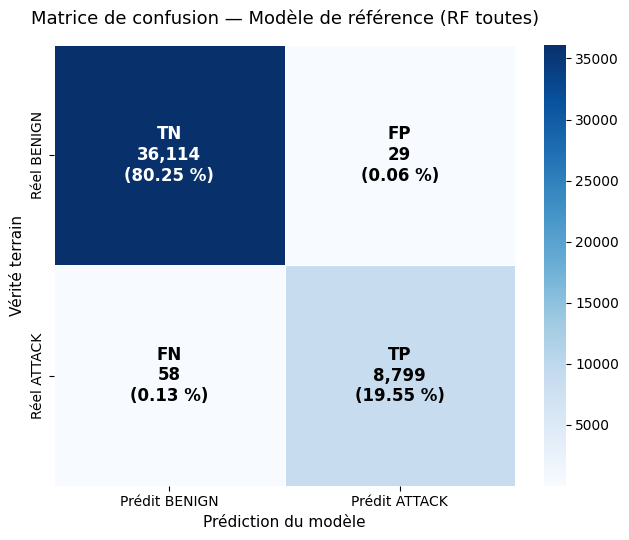


=== Analyse de la matrice ===
TN (BENIGN bien classés)     : 36,114
FP (fausses alertes)         : 29
FN (attaques manquées)       : 58
TP (attaques bien détectées) : 8,799
Total                        : 45,000
Sensibilité (Recall ATTACK)  : 0.9935
Spécificité (Recall BENIGN)  : 0.9992
Taux de faux négatifs        : 0.0065

✅ Matrice de référence sauvegardée.


In [12]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# --- Sécurité après redémarrage du noyau ---
required = ['y_test', 'y_pred_full']
missing = [v for v in required if v not in globals()]
if missing:
    raise RuntimeError(f"Variables manquantes : {missing}. Exécutez la cellule 15.")

# ============================================================
# Fonction utilitaire (réutilisée en 32 pour le modèle BPSO)
# ============================================================
def afficher_matrice_confusion(y_true, y_pred, titre, nom_fichier):
    """
    Affiche et sauvegarde une matrice de confusion annotée.
    Retourne (tn, fp, fn, tp).
    """
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    total = cm.sum()

    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    sns.heatmap(cm, annot=False, fmt='d', cmap='Blues', ax=ax,
                cbar=True, linewidths=0.5, linecolor='white',
                xticklabels=['Prédit BENIGN', 'Prédit ATTACK'],
                yticklabels=['Réel BENIGN', 'Réel ATTACK'])

    labels = [['TN', 'FP'], ['FN', 'TP']]
    for i in range(2):
        for j in range(2):
            val = cm[i, j]
            pct = 100 * val / total
            txt = f'{labels[i][j]}\n{val:,}\n({pct:.2f} %)'
            color = 'white' if val > cm.max() / 2 else 'black'
            ax.text(j + 0.5, i + 0.5, txt,
                    ha='center', va='center',
                    fontsize=12, fontweight='bold', color=color)

    ax.set_title(titre, fontsize=13, pad=15)
    ax.set_xlabel('Prédiction du modèle', fontsize=11)
    ax.set_ylabel('Vérité terrain', fontsize=11)
    plt.tight_layout()
    plt.savefig(nom_fichier, dpi=300)
    plt.show()

    print(f'\n=== Analyse de la matrice ===')
    print(f'TN (BENIGN bien classés)     : {tn:,}')
    print(f'FP (fausses alertes)         : {fp:,}')
    print(f'FN (attaques manquées)       : {fn:,}')
    print(f'TP (attaques bien détectées) : {tp:,}')
    print(f'Total                        : {total:,}')
    print(f'Sensibilité (Recall ATTACK)  : {tp / (tp + fn):.4f}')
    print(f'Spécificité (Recall BENIGN)  : {tn / (tn + fp):.4f}')
    print(f'Taux de faux négatifs        : {fn / (tp + fn):.4f}')

    return tn, fp, fn, tp

# ============================================================
# Application au modèle de référence
# ============================================================
tn_full, fp_full, fn_full, tp_full = afficher_matrice_confusion(
    y_test, y_pred_full,
    'Matrice de confusion — Modèle de référence (RF toutes)',
    'fig13_confusion_reference.png'
)

print('\n✅ Matrice de référence sauvegardée.')

Nombre de caractéristiques analysées : 78

Top 20 des caractéristiques les plus importantes :
 Destination Port              0.063804
 Packet Length Variance        0.060018
 Bwd Packet Length Std         0.049048
Init_Win_bytes_forward         0.047151
 Average Packet Size           0.046428
 Packet Length Mean            0.044668
 Init_Win_bytes_backward       0.040388
 Bwd Packet Length Mean        0.039744
 Fwd Packet Length Mean        0.034839
 Packet Length Std             0.033428
 Subflow Fwd Bytes             0.032640
 Max Packet Length             0.031549
 Fwd Packet Length Max         0.030442
 Fwd Packet Length Min         0.028791
 Bwd Header Length             0.027424
 Subflow Bwd Bytes             0.021237
Bwd Packet Length Max          0.020986
 Min Packet Length             0.020789
 Avg Bwd Segment Size          0.020264
Total Length of Fwd Packets    0.019999
dtype: float64

Top 5 (détail) :
  1.  Destination Port                   : 0.063804
  2.  Packet Length V

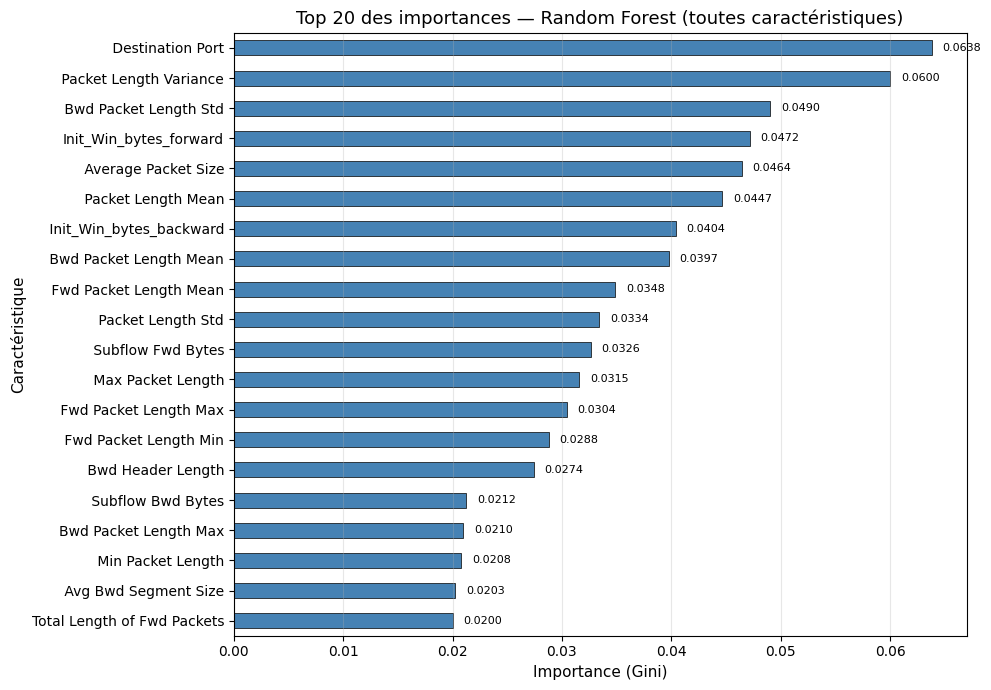


✅ Importances calculées et graphique sauvegardé.


In [13]:

import pandas as pd
import matplotlib.pyplot as plt

# --- Sécurité après redémarrage du noyau ---
required = ['rf_full', 'feature_cols']
missing = [v for v in required if v not in globals()]
if missing:
    raise RuntimeError(
        f"Variables manquantes : {missing}. Exécutez la cellule 14."
    )

# ============================================================
# Classement global des importances
# ============================================================
importances_full = pd.Series(
    rf_full.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

print(f'Nombre de caractéristiques analysées : {len(importances_full)}')
print(f'\nTop 20 des caractéristiques les plus importantes :')
print(importances_full.head(20).round(6))

print(f'\nTop 5 (détail) :')
for i, (nom, imp) in enumerate(importances_full.head(5).items(), 1):
    print(f'  {i}. {nom:35s} : {imp:.6f}')

print(f'\nCaractéristiques avec importance < 0.001 : '
      f'{(importances_full < 0.001).sum()}')

# ============================================================
# Graphique des 20 principales
# ============================================================
fig, ax = plt.subplots(figsize=(10, 7))
top20 = importances_full.head(20)
top20[::-1].plot(kind='barh', ax=ax, color='steelblue',
                 edgecolor='black', linewidth=0.5)

ax.set_title('Top 20 des importances — Random Forest (toutes caractéristiques)',
             fontsize=13)
ax.set_xlabel('Importance (Gini)', fontsize=11)
ax.set_ylabel('Caractéristique', fontsize=11)
ax.grid(axis='x', alpha=0.3)

# Annotation des valeurs
for i, v in enumerate(top20[::-1].values):
    ax.text(v + 0.001, i, f'{v:.4f}', va='center', fontsize=8)

plt.tight_layout()
plt.savefig('fig_top20_importances_full.png', dpi=300)
plt.show()

# ============================================================
# Vérifications
# ============================================================
assert len(importances_full) == len(feature_cols)
assert abs(importances_full.sum() - 1.0) < 1e-3, \
    "Les importances doivent sommer à 1."

print('\n✅ Importances calculées et graphique sauvegardé.')

## 19. Fondements théoriques du Particle Swarm Optimization (PSO) et du Binary PSO (BPSO)

### 19.1 PSO — Particle Swarm Optimization (Kennedy & Eberhart, 1995)

Le PSO est une métaheuristique d'optimisation inspirée du vol groupé d'oiseaux ou du banc de poissons. Elle cherche à minimiser une fonction objectif $f$ en maintenant un **essaim** de **particules** qui explorent l'espace.

Chaque particule $i$ possède :
- une position $x_i$ (solution candidate),
- une vitesse $v_i$ (direction et amplitude du déplacement),
- une mémoire de sa meilleure position personnelle $pbest_i$,
- une connaissance de la meilleure position globale $gbest$.

À chaque itération $t$, on met à jour la vitesse puis la position :

$$
v_{ij}(t+1) = w \cdot v_{ij}(t)
             + c_1 \cdot r_{1} \cdot \bigl(pbest_{ij} - x_{ij}(t)\bigr)
             + c_2 \cdot r_{2} \cdot \bigl(gbest_j - x_{ij}(t)\bigr)
$$

$$
x_{ij}(t+1) = x_{ij}(t) + v_{ij}(t+1)
$$

avec :
- $w$ : **inertie** (poids de la vitesse précédente) — contrôle l'exploration,
- $c_1$ : coefficient **cognitif** (attraction vers $pbest_i$),
- $c_2$ : coefficient **social** (attraction vers $gbest$),
- $r_1, r_2 \sim \mathcal{U}(0,1)$ : aléatoires pour la diversité.

### 19.2 Binary PSO (Kennedy & Eberhart, 1997)

Le PSO original travaille dans $\mathbb{R}^n$. Pour la **sélection de caractéristiques**, chaque particule doit être un **masque binaire** $\{0,1\}^D$ : bit à 1 = caractéristique sélectionnée.

Le BPSO conserve la vitesse **continue** mais transforme la position via une **sigmoïde** :

$$
S\bigl(v_{ij}(t+1)\bigr) = \frac{1}{1 + e^{-v_{ij}(t+1)}}
$$

La position binaire est ensuite :

$$
x_{ij}(t+1) =
\begin{cases}
1 & \text{si } r < S\bigl(v_{ij}(t+1)\bigr) \\
0 & \text{sinon}
\end{cases}
$$

avec $r \sim \mathcal{U}(0,1)$.

**Interprétation** : une vitesse **positive forte** → $S \to 1$ → forte probabilité que la caractéristique soit **sélectionnée**. Une vitesse **négative forte** → $S \to 0$ → forte probabilité qu'elle soit **exclue**.

### 19.3 Fonction de fitness utilisée

Pour comparer deux masques, on définit une fonction objectif à **minimiser** :

$$
J(S) = \alpha \cdot \bigl(1 - F1_{\text{val}}(S)\bigr)
     + (1-\alpha) \cdot \frac{|S|}{D}
$$

où :
- $S$ : masque binaire (sous-ensemble de caractéristiques),
- $F1_{\text{val}}(S)$ : F1-score obtenu par un Random Forest entraîné sur les features de $S$, évalué sur le **jeu de validation**,
- $|S|$ : nombre de bits à 1 dans $S$,
- $D$ : nombre total de caractéristiques,
- $\alpha \in [0,1]$ : poids relatif.

Avec $\alpha = 0.90$ (choix retenu) :
- **90 %** du score vient de la performance (F1),
- **10 %** du score pénalise la taille du sous-ensemble.

**Compromis** : $\alpha$ élevé → solutions performantes mais denses. $\alpha$ faible → solutions compactes mais potentiellement moins performantes. **0,90 est un réglage standard** pour ne pas sacrifier la performance en NIDS.

### 19.4 Ce que le BPSO doit trouver

Un masque binaire $S^*$ tel que $J(S^*)$ soit **minimal** — c'est-à-dire un compromis optimal entre **peu de caractéristiques** et **F1 élevé**. Le jeu de test n'intervient **jamais** dans cette recherche.

In [15]:

import numpy as np

# --- Sécurité après redémarrage du noyau ---
if 'SEED' not in globals():
    SEED = 2026
    print(f'ℹ️  SEED redéfini = {SEED}')

if 'X_train' not in globals():
    raise RuntimeError("X_train absent — exécutez la cellule 12.")

# ============================================================
# Hyperparamètres BPSO
# ============================================================
N_PARTICULES   = 10         # taille de l'essaim
N_ITERATIONS   = 20         # nombre d'itérations
W_INERTIE      = 0.72       # inertie (exploration vs exploitation)
C1_COGNITIF    = 1.49       # coefficient cognitif
C2_SOCIAL      = 1.49       # coefficient social
ALPHA_FITNESS  = 0.90       # poids de la performance dans J(S)
V_MAX          = 4.0        # clippage de la vitesse (évite saturation sigmoïde)

# ============================================================
# Budget de calcul et vérifications
# ============================================================
D = X_train.shape[1]
budget_evaluations = N_PARTICULES * (N_ITERATIONS + 1)  # +1 = init

print('=== Paramètres du BPSO ===')
print(f'Dimension (D)                : {D}')
print(f'Particules                   : {N_PARTICULES}')
print(f'Itérations                   : {N_ITERATIONS}')
print(f'Inertie (w)                  : {W_INERTIE}')
print(f'Coefficient cognitif (c1)    : {C1_COGNITIF}')
print(f'Coefficient social (c2)      : {C2_SOCIAL}')
print(f'Alpha fitness                : {ALPHA_FITNESS}')
print(f'V max                        : {V_MAX}')
print(f'Budget total d\'évaluations   : {budget_evaluations}')
print(f'Seed                         : {SEED}')

# ============================================================
# Vérifications
# ============================================================
assert N_PARTICULES >= 2
assert N_ITERATIONS >= 1
assert 0 < W_INERTIE <= 1
assert 0 < C1_COGNITIF < 3
assert 0 < C2_SOCIAL < 3
assert 0 < ALPHA_FITNESS <= 1
assert 0 < V_MAX <= 10
assert D == X_train.shape[1]

print('\n✅ Paramètres BPSO validés.')
print(f'\n⚠️  Temps estimé : chaque évaluation ≈ entraînement RF rapide (~0,1-0,3 s)')
print(f'   {budget_evaluations} évaluations → ~{budget_evaluations * 0.2:.0f} à '
      f'{budget_evaluations * 0.4:.0f} s (sans cache)')

=== Paramètres du BPSO ===
Dimension (D)                : 78
Particules                   : 10
Itérations                   : 20
Inertie (w)                  : 0.72
Coefficient cognitif (c1)    : 1.49
Coefficient social (c2)      : 1.49
Alpha fitness                : 0.9
V max                        : 4.0
Budget total d'évaluations   : 210
Seed                         : 2026

✅ Paramètres BPSO validés.

⚠️  Temps estimé : chaque évaluation ≈ entraînement RF rapide (~0,1-0,3 s)
   210 évaluations → ~42 à 84 s (sans cache)


In [16]:
# ============================================================
#  — Initialisation de l'essaim binaire
# Chaque particule = masque binaire de longueur D
# ============================================================
import numpy as np

if 'SEED' not in globals():
    SEED = 2026
if 'D' not in globals():
    raise RuntimeError("D absent — exécutez la cellule 20.")
if 'N_PARTICULES' not in globals():
    raise RuntimeError("N_PARTICULES absent — exécutez la cellule 20.")

def initialiser_essaim(n_particules, dimension, seed=SEED):
    rng = np.random.default_rng(seed)
    positions = rng.integers(0, 2, size=(n_particules, dimension)).astype(np.int8)
    vitesses  = rng.uniform(-1.0, 1.0, size=(n_particules, dimension))
    return positions, vitesses

positions, vitesses = initialiser_essaim(N_PARTICULES, D)

print(f'Shape positions : {positions.shape}')
print(f'Shape vitesses  : {vitesses.shape}')
print(f'Nombre moyen de bits à 1 (init) : {positions.sum(axis=1).mean():.2f} / {D}')
print(f'\nParticule 0 (extrait 20 bits) : {positions[0, :20]}')

assert positions.shape == (N_PARTICULES, D)
assert vitesses.shape  == (N_PARTICULES, D)
assert set(np.unique(positions)).issubset({0, 1})
print('\n✅ Encodage binaire validé.')

Shape positions : (10, 78)
Shape vitesses  : (10, 78)
Nombre moyen de bits à 1 (init) : 37.60 / 78

Particule 0 (extrait 20 bits) : [1 0 0 1 0 0 0 0 1 0 1 1 1 1 1 0 1 1 0 0]

✅ Encodage binaire validé.


In [17]:

import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

required = ['X_train','y_train','X_val','y_val','SEED','D','ALPHA_FITNESS']
missing = [v for v in required if v not in globals()]
if missing:
    raise RuntimeError(f"Variables manquantes : {missing}.")

def fitness(masque, X_tr, y_tr, X_va, y_va, alpha=ALPHA_FITNESS, d_total=D):
    """Calcule (J, F1_val, n_selected). Retourne J=1.0 si masque vide."""
    idx = np.where(masque == 1)[0]
    if len(idx) == 0:
        return 1.0, 0.0, 0

    X_tr_sub = X_tr.iloc[:, idx]
    X_va_sub = X_va.iloc[:, idx]

    rf = RandomForestClassifier(
        n_estimators=50, max_depth=None,
        random_state=SEED, n_jobs=-1,
        class_weight='balanced_subsample'
    )
    rf.fit(X_tr_sub, y_tr)
    y_pred = rf.predict(X_va_sub)
    f1 = f1_score(y_va, y_pred, zero_division=0)

    n_sel = len(idx)
    j = alpha * (1.0 - f1) + (1.0 - alpha) * (n_sel / d_total)
    return float(j), float(f1), int(n_sel)

# Test sur un masque aléatoire
j_t, f1_t, n_t = fitness(positions[0], X_train, y_train, X_val, y_val)
print(f'Masque aléatoire | J={j_t:.4f} | F1={f1_t:.4f} | |S|={n_t}')
print('\n✅ Fonction de fitness opérationnelle.')

Masque aléatoire | J=0.0529 | F1=0.9968 | |S|=39

✅ Fonction de fitness opérationnelle.


In [18]:
# ============================================================
# CELLULE 23 — Sigmoïde, vitesses et positions binaires
# ============================================================
import numpy as np

if 'W_INERTIE' not in globals():
    raise RuntimeError("W_INERTIE absent — exécutez la cellule 20.")
if 'V_MAX' not in globals():
    V_MAX = 4.0

def sigmoide(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -500, 500)))

def mettre_a_jour_particule(position, vitesse, pbest, gbest, w, c1, c2, rng, v_max=V_MAX):
    r1 = rng.random(position.shape)
    r2 = rng.random(position.shape)

    v_new = (w * vitesse
             + c1 * r1 * (pbest - position)
             + c2 * r2 * (gbest - position))
    v_new = np.clip(v_new, -v_max, v_max)

    proba = sigmoide(v_new)
    pos_new = (rng.random(position.shape) < proba).astype(np.int8)
    return pos_new, v_new

# Test unitaire
pos_t, vit_t = mettre_a_jour_particule(
    positions[0], vitesses[0], positions[0], positions[1],
    W_INERTIE, C1_COGNITIF, C2_SOCIAL, np.random.default_rng(SEED)
)
print(f'Position de test (extrait) : {pos_t[:20]}')
print(f'Vitesse  de test (extrait) : {np.round(vit_t[:5], 3)}')
assert set(np.unique(pos_t)).issubset({0, 1})
print('\n✅ Mise à jour binaire validée.')

Position de test (extrait) : [0 1 1 0 0 1 1 0 0 1 0 1 1 0 0 1 0 0 0 1]
Vitesse  de test (extrait) : [ 0.335 -0.188  0.142 -0.173  0.2  ]

✅ Mise à jour binaire validée.


In [19]:
# ============================================================
# CELLULE — Cache pour éviter les réévaluations redondantes
#============================================================
cache_fitness = {}

def evaluer_avec_cache(masque, X_tr, y_tr, X_va, y_va):
    cle = tuple(masque.tolist())
    if cle in cache_fitness:
        return cache_fitness[cle]
    resultat = fitness(masque, X_tr, y_tr, X_va, y_va)
    cache_fitness[cle] = resultat
    return resultat

# Test
r1 = evaluer_avec_cache(positions[0], X_train, y_train, X_val, y_val)
r2 = evaluer_avec_cache(positions[0], X_train, y_train, X_val, y_val)
assert r1 == r2
print(f'Cache fonctionnel. Entrées : {len(cache_fitness)}')
print('\n✅ Cache validé.')

Cache fonctionnel. Entrées : 1

✅ Cache validé.


In [20]:

# ============================================================
import numpy as np

if 'evaluer_avec_cache' not in globals():
    raise RuntimeError("Exécutez la cellule 24.")

masques = {
    'aléatoire':         positions[0].copy(),
    'tout sélectionné':  np.ones(D, dtype=np.int8),
    'aucun sélectionné': np.zeros(D, dtype=np.int8)
}
for nom, m in masques.items():
    j, f1, n = evaluer_avec_cache(m, X_train, y_train, X_val, y_val)
    print(f'{nom:20s} | J={j:.4f} | F1={f1:.4f} | |S|={n}')

j_vide, _, _ = evaluer_avec_cache(np.zeros(D, dtype=np.int8),
                                  X_train, y_train, X_val, y_val)
assert j_vide == 1.0
print('\n✅ Comportement du masque vide validé (J=1.0).')

aléatoire            | J=0.0529 | F1=0.9968 | |S|=39
tout sélectionné     | J=0.1034 | F1=0.9963 | |S|=78
aucun sélectionné    | J=1.0000 | F1=0.0000 | |S|=0

✅ Comportement du masque vide validé (J=1.0).


In [21]:

# ============================================================
import time
import numpy as np
import pandas as pd

required = ['positions','vitesses','N_PARTICULES','N_ITERATIONS','D',
            'W_INERTIE','C1_COGNITIF','C2_SOCIAL','SEED',
            'evaluations_curve' if False else 'X_train']
if 'positions' not in globals():
    raise RuntimeError("Exécutez les cellules 21 à 25.")

# Réinitialiser un essaim propre (indépendant des tests 21/25)
rng = np.random.default_rng(SEED)
positions, vitesses = initialiser_essaim(N_PARTICULES, D, seed=SEED)

# Évaluations initiales
fitness_perso = np.full(N_PARTICULES, np.inf)
f1_perso      = np.zeros(N_PARTICULES)
n_perso       = np.zeros(N_PARTICULES, dtype=int)

for i in range(N_PARTICULES):
    j, f1, n = evaluer_avec_cache(positions[i], X_train, y_train, X_val, y_val)
    fitness_perso[i] = j; f1_perso[i] = f1; n_perso[i] = n

pbest = positions.copy()
idx_best = int(np.argmin(fitness_perso))
gbest = pbest[idx_best].copy()
fitness_gbest = float(fitness_perso[idx_best])
f1_gbest = float(f1_perso[idx_best])
n_gbest = int(n_perso[idx_best])

# Historiques
convergence_curve = []
f1_val_curve      = []
n_features_curve  = []
temps_curve       = []
evaluations_curve = []
historique        = []

n_evaluations_total = N_PARTICULES
t_debut = time.time()

for iteration in range(N_ITERATIONS):
    t_iter = time.time()

    for i in range(N_PARTICULES):
        positions[i], vitesses[i] = mettre_a_jour_particule(
            positions[i], vitesses[i], pbest[i], gbest,
            W_INERTIE, C1_COGNITIF, C2_SOCIAL, rng
        )
        j, f1, n = evaluer_avec_cache(positions[i], X_train, y_train, X_val, y_val)
        n_evaluations_total += 1

        if j < fitness_perso[i]:
            fitness_perso[i] = j
            f1_perso[i] = f1
            n_perso[i] = n
            pbest[i] = positions[i].copy()

    idx_best = int(np.argmin(fitness_perso))
    if fitness_perso[idx_best] < fitness_gbest:
        fitness_gbest = float(fitness_perso[idx_best])
        f1_gbest = float(f1_perso[idx_best])
        n_gbest = int(n_perso[idx_best])
        gbest = pbest[idx_best].copy()

    temps_iter = time.time() - t_iter
    convergence_curve.append(fitness_gbest)
    f1_val_curve.append(f1_gbest)
    n_features_curve.append(n_gbest)
    temps_curve.append(temps_iter)
    evaluations_curve.append(n_evaluations_total)

    historique.append({
        'iteration': iteration + 1,
        'fitness_gbest': fitness_gbest,
        'f1_val_gbest': f1_gbest,
        'n_features': n_gbest,
        'temps_iteration_s': temps_iter,
        'evaluations_cumulees': n_evaluations_total,
        'taille_cache': len(cache_fitness),
    })

    print(f'It {iteration+1:02d}/{N_ITERATIONS} | J*={fitness_gbest:.4f} | '
          f'F1={f1_gbest:.4f} | |S|={n_gbest:2d} | t={temps_iter:.1f}s | '
          f'evals={n_evaluations_total}')

temps_total_pso = time.time() - t_debut
df_historique = pd.DataFrame(historique)

print(f'\n=== BPSO terminé ===')
print(f'Durée totale            : {temps_total_pso:.1f} s')
print(f'Évaluations totales     : {n_evaluations_total}')
print(f'Entrées dans le cache   : {len(cache_fitness)}')
print(f'Fitness finale          : {fitness_gbest:.4f}')
print(f'F1 validation final     : {f1_gbest:.4f}')
print(f'Caractéristiques        : {n_gbest}/{D}')

assert 'gbest' in locals() and gbest is not None
assert len(convergence_curve) == N_ITERATIONS
assert len(f1_val_curve) == N_ITERATIONS
assert len(n_features_curve) == N_ITERATIONS
print('\n✅ Variables de convergence disponibles.')

It 01/20 | J*=0.0449 | F1=0.9957 | |S|=32 | t=228.1s | evals=20
It 02/20 | J*=0.0425 | F1=0.9955 | |S|=30 | t=238.9s | evals=30
It 03/20 | J*=0.0408 | F1=0.9931 | |S|=27 | t=215.3s | evals=40
It 04/20 | J*=0.0388 | F1=0.9940 | |S|=26 | t=228.2s | evals=50
It 05/20 | J*=0.0376 | F1=0.9924 | |S|=24 | t=216.2s | evals=60
It 06/20 | J*=0.0376 | F1=0.9924 | |S|=24 | t=228.7s | evals=70
It 07/20 | J*=0.0376 | F1=0.9924 | |S|=24 | t=216.9s | evals=80
It 08/20 | J*=0.0376 | F1=0.9924 | |S|=24 | t=220.7s | evals=90
It 09/20 | J*=0.0376 | F1=0.9924 | |S|=24 | t=205.8s | evals=100
It 10/20 | J*=0.0376 | F1=0.9924 | |S|=24 | t=214.3s | evals=110
It 11/20 | J*=0.0376 | F1=0.9924 | |S|=24 | t=209.9s | evals=120
It 12/20 | J*=0.0376 | F1=0.9924 | |S|=24 | t=219.8s | evals=130
It 13/20 | J*=0.0376 | F1=0.9924 | |S|=24 | t=218.5s | evals=140
It 14/20 | J*=0.0376 | F1=0.9924 | |S|=24 | t=211.3s | evals=150
It 15/20 | J*=0.0376 | F1=0.9924 | |S|=24 | t=197.4s | evals=160
It 16/20 | J*=0.0376 | F1=0.9924 

In [22]:

import numpy as np
import pandas as pd

if 'gbest' not in globals():
    raise RuntimeError("gbest absent — exécutez la cellule 26.")

best_position = gbest.copy()
selected_indices  = np.where(best_position == 1)[0]
selected_features = [feature_cols[i] for i in selected_indices]

print(f'Nombre de caractéristiques sélectionnées : {len(selected_features)} / {D}')
print(f'Fitness finale : {fitness_gbest:.4f}')
print(f'F1 validation associé : {f1_gbest:.4f}')
print(f'\nListe des caractéristiques retenues :')
for i, f in enumerate(selected_features, 1):
    print(f'  {i:2d}. {f}')

pd.Series(selected_features, name='feature_selectionnee').to_csv(
    'features_selectionnees_bpso.csv', index=False)
print('\n✅ Liste sauvegardée dans features_selectionnees_bpso.csv')

Nombre de caractéristiques sélectionnées : 26 / 78
Fitness finale : 0.0363
F1 validation associé : 0.9967

Liste des caractéristiques retenues :
   1.  Destination Port
   2.  Flow Duration
   3.  Total Fwd Packets
   4. Total Length of Fwd Packets
   5.  Fwd Packet Length Std
   6. Bwd Packet Length Max
   7.  Flow Packets/s
   8.  Fwd IAT Max
   9.  Fwd IAT Min
  10.  Bwd IAT Mean
  11. Fwd PSH Flags
  12. Fwd Packets/s
  13.  Min Packet Length
  14.  Packet Length Mean
  15.  Packet Length Variance
  16.  RST Flag Count
  17.  PSH Flag Count
  18.  Average Packet Size
  19.  Fwd Avg Bulk Rate
  20.  Subflow Bwd Packets
  21. Init_Win_bytes_forward
  22.  Init_Win_bytes_backward
  23.  act_data_pkt_fwd
  24. Idle Mean
  25.  Idle Std
  26.  Idle Max

✅ Liste sauvegardée dans features_selectionnees_bpso.csv


=== Bilan de la sélection ===
Caractéristiques initiales     : 78
Caractéristiques sélectionnées : 26
Caractéristiques éliminées     : 52
Taux de réduction              : 66.67 %


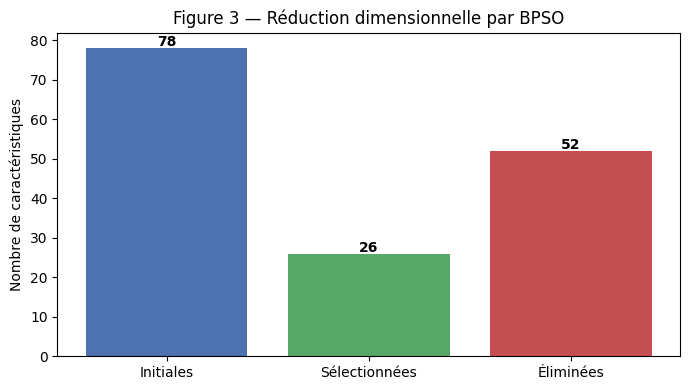

In [23]:

import matplotlib.pyplot as plt

n_initial = D
n_selected = len(selected_features)
n_eliminated = n_initial - n_selected
reduction_pct = 100 * n_eliminated / n_initial

print('=== Bilan de la sélection ===')
print(f'Caractéristiques initiales     : {n_initial}')
print(f'Caractéristiques sélectionnées : {n_selected}')
print(f'Caractéristiques éliminées     : {n_eliminated}')
print(f'Taux de réduction              : {reduction_pct:.2f} %')

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(['Initiales', 'Sélectionnées', 'Éliminées'],
              [n_initial, n_selected, n_eliminated],
              color=['#4C72B0', '#55A868', '#C44E52'])
for bar, v in zip(bars, [n_initial, n_selected, n_eliminated]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            str(v), ha='center', fontweight='bold')
ax.set_title('Figure 3 — Réduction dimensionnelle par BPSO')
ax.set_ylabel('Nombre de caractéristiques')
plt.tight_layout()
plt.savefig('fig03_reduction_dimensionnelle.png', dpi=300)
plt.show()

In [24]:
# ============================================================
import time
from sklearn.ensemble import RandomForestClassifier

if 'selected_features' not in globals():
    raise RuntimeError("selected_features absent — exécutez la cellule 27.")
if 'RF_PARAMS' not in globals():
    raise RuntimeError("RF_PARAMS absent — exécutez la cellule 14.")

X_train_sel = X_train[selected_features]
X_val_sel   = X_val[selected_features]
X_test_sel  = X_test[selected_features]

rf_bpso = RandomForestClassifier(**RF_PARAMS)

t0 = time.time()
rf_bpso.fit(X_train_sel, y_train)
train_time_bpso = time.time() - t0

print(f'Entraînement BPSO terminé en {train_time_bpso:.2f} s')
print(f'Caractéristiques : {len(selected_features)} / {D}')
print(f'Arbres : {len(rf_bpso.estimators_)}')
print('\n✅ Modèle BPSO entraîné.')

Entraînement BPSO terminé en 61.20 s
Caractéristiques : 26 / 78
Arbres : 100

✅ Modèle BPSO entraîné.


In [25]:
# ============================================================
# CELLULE — Métriques du modèle BPSO sur le test
# ============================================================
import time
import numpy as np

if 'rf_bpso' not in globals():
    raise RuntimeError("rf_bpso absent — exécutez la cellule 29.")
if 'calculer_metriques' not in globals():
    raise RuntimeError("calculer_metriques absent — exécutez la cellule 15.")

t0 = time.time()
y_pred_bpso = rf_bpso.predict(X_test_sel)
pred_time_bpso = time.time() - t0
y_proba_bpso = rf_bpso.predict_proba(X_test_sel)[:, 1]

metrics_bpso = calculer_metriques(y_test, y_pred_bpso, y_proba_bpso)

print('=== Métriques BPSO (test) ===')
for k, v in metrics_bpso.items():
    print(f'  {k:22s} : {v:.4f}')
print(f'  {"temps_train":22s} : {train_time_bpso:.2f} s')
print(f'  {"temps_predict":22s} : {pred_time_bpso:.2f} s')

for k, v in metrics_bpso.items():
    assert 0 <= v <= 1
print('\n✅ Métriques BPSO calculées.')

=== Métriques BPSO (test) ===
  accuracy               : 0.9983
  precision              : 0.9957
  recall                 : 0.9956
  f1                     : 0.9957
  roc_auc                : 0.9998
  average_precision      : 0.9984
  temps_train            : 61.20 s
  temps_predict          : 0.59 s

✅ Métriques BPSO calculées.


In [26]:

# ============================================================
import pandas as pd
from sklearn.metrics import classification_report

if 'y_pred_bpso' not in globals():
    raise RuntimeError("Exécutez la cellule 30.")

print('=== Rapport de classification — Modèle BPSO ===\n')
print(classification_report(
    y_test, y_pred_bpso,
    target_names=['BENIGN (0)', 'ATTACK (1)'],
    digits=4
))

report_dict_bpso = classification_report(
    y_test, y_pred_bpso,
    target_names=['BENIGN (0)', 'ATTACK (1)'],
    digits=4, output_dict=True)
report_df_bpso = pd.DataFrame(report_dict_bpso).T.round(4)

a = report_dict_bpso['ATTACK (1)']
print('=== Focus ATTACK ===')
print(f'Precision : {a["precision"]:.4f}')
print(f'Recall    : {a["recall"]:.4f}')
print(f'F1        : {a["f1-score"]:.4f}')
print(f'Support   : {int(a["support"]):,}')
print('\n✅ Rapport BPSO validé.')

=== Rapport de classification — Modèle BPSO ===

              precision    recall  f1-score   support

  BENIGN (0)     0.9989    0.9989    0.9989     36143
  ATTACK (1)     0.9957    0.9956    0.9957      8857

    accuracy                         0.9983     45000
   macro avg     0.9973    0.9973    0.9973     45000
weighted avg     0.9983    0.9983    0.9983     45000

=== Focus ATTACK ===
Precision : 0.9957
Recall    : 0.9956
F1        : 0.9957
Support   : 8,857

✅ Rapport BPSO validé.


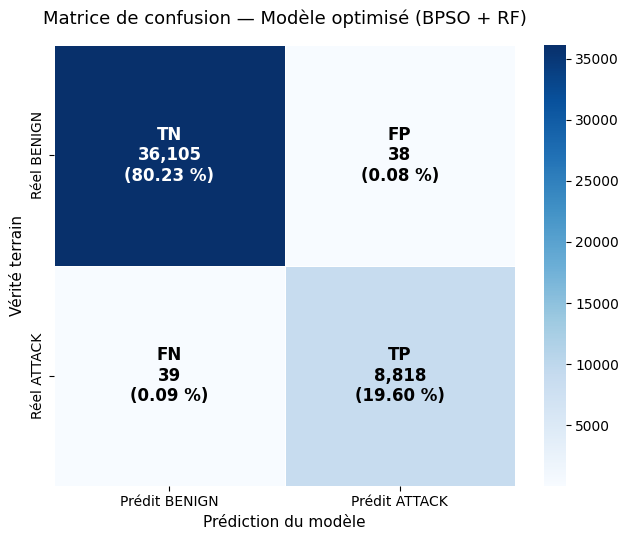


=== Analyse de la matrice ===
TN (BENIGN bien classés)     : 36,105
FP (fausses alertes)         : 38
FN (attaques manquées)       : 39
TP (attaques bien détectées) : 8,818
Total                        : 45,000
Sensibilité (Recall ATTACK)  : 0.9956
Spécificité (Recall BENIGN)  : 0.9989
Taux de faux négatifs        : 0.0044

✅ Matrice BPSO sauvegardée.


In [27]:

if 'afficher_matrice_confusion' not in globals():
    raise RuntimeError("Exécutez la cellule 17.")

tn_bpso, fp_bpso, fn_bpso, tp_bpso = afficher_matrice_confusion(
    y_test, y_pred_bpso,
    'Matrice de confusion — Modèle optimisé (BPSO + RF)',
    'fig14_confusion_bpso.png'
)
print('\n✅ Matrice BPSO sauvegardée.')

In [28]:

import pandas as pd

required = ['metrics_full','metrics_bpso','train_time_full','train_time_bpso',
            'pred_time_full','pred_time_bpso','D','selected_features']
missing = [v for v in required if v not in globals()]
if missing:
    raise RuntimeError(f"Variables manquantes : {missing}.")

comparaison = pd.DataFrame({
    'Modèle': ['RF (toutes)', 'RF + BPSO'],
    'Accuracy':           [metrics_full['accuracy'],           metrics_bpso['accuracy']],
    'Precision':          [metrics_full['precision'],          metrics_bpso['precision']],
    'Recall':             [metrics_full['recall'],             metrics_bpso['recall']],
    'F1-score':           [metrics_full['f1'],                 metrics_bpso['f1']],
    'ROC-AUC':            [metrics_full['roc_auc'],            metrics_bpso['roc_auc']],
    'Avg Precision':      [metrics_full['average_precision'],  metrics_bpso['average_precision']],
    'Nb caractéristiques':[D,                                  len(selected_features)],
    'Temps entraînement (s)': [train_time_full, train_time_bpso],
    'Temps prédiction (s)':   [pred_time_full, pred_time_bpso],
})

print('=== Tableau comparatif ===')
display(comparaison.round(4))
comparaison.to_csv('comparaison_metriques.csv', index=False)
print('\n✅ Sauvegardé dans comparaison_metriques.csv')

=== Tableau comparatif ===


,Modèle,Accuracy,Precision,Recall,F1-score,ROC-AUC,Avg Precision,Nb caractéristiques,Temps entraînement (s),Temps prédiction (s)
0,RF (toutes),0.9981,0.9967,0.9935,0.9951,0.9998,0.9981,78,73.1397,1.0972
1,RF + BPSO,0.9983,0.9957,0.9956,0.9957,0.9998,0.9984,26,61.2027,0.5864



✅ Sauvegardé dans comparaison_metriques.csv


In [29]:

delta_f1     = metrics_bpso['f1'] - metrics_full['f1']
delta_recall = metrics_bpso['recall'] - metrics_full['recall']
delta_auc    = metrics_bpso['roc_auc'] - metrics_full['roc_auc']
gain_t_train = train_time_full - train_time_bpso
gain_t_pred  = pred_time_full - pred_time_bpso
reduction    = 100 * (D - len(selected_features)) / D

print('=== Analyse des variations (BPSO − Référence) ===')
print(f'Δ F1-score          : {delta_f1:+.4f}')
print(f'Δ Recall (ATTACK)   : {delta_recall:+.4f}')
print(f'Δ ROC-AUC           : {delta_auc:+.4f}')
print(f'Gain temps train    : {gain_t_train:+.2f} s')
print(f'Gain temps prédict  : {gain_t_pred:+.2f} s')
print(f'Réduction dimension : {reduction:.2f} %')

print('\n=== Interprétation automatique ===')
if delta_f1 > 0.005:
    print('- F1 BPSO > F1 référence : la sélection a amélioré la généralisation.')
elif delta_f1 < -0.005:
    print('- F1 BPSO < F1 référence : la réduction a un coût en performance.')
else:
    print('- F1 stable (|Δ| ≤ 0,005) : la sélection n\'a pas dégradé la performance.')

if delta_recall >= -0.01:
    print('- Recall ATTACK maintenu (Δ ≥ −0,01) : détection préservée.')
else:
    print('- Recall ATTACK dégradé : risque accru de faux négatifs.')

print(f'- {D - len(selected_features)} caractéristiques éliminées ({reduction:.1f} %).')
print(f'- Gain temps entraînement : {gain_t_train:+.2f} s.')

=== Analyse des variations (BPSO − Référence) ===
Δ F1-score          : +0.0006
Δ Recall (ATTACK)   : +0.0021
Δ ROC-AUC           : +0.0000
Gain temps train    : +11.94 s
Gain temps prédict  : +0.51 s
Réduction dimension : 66.67 %

=== Interprétation automatique ===
- F1 stable (|Δ| ≤ 0,005) : la sélection n'a pas dégradé la performance.
- Recall ATTACK maintenu (Δ ≥ −0,01) : détection préservée.
- 52 caractéristiques éliminées (66.7 %).
- Gain temps entraînement : +11.94 s.


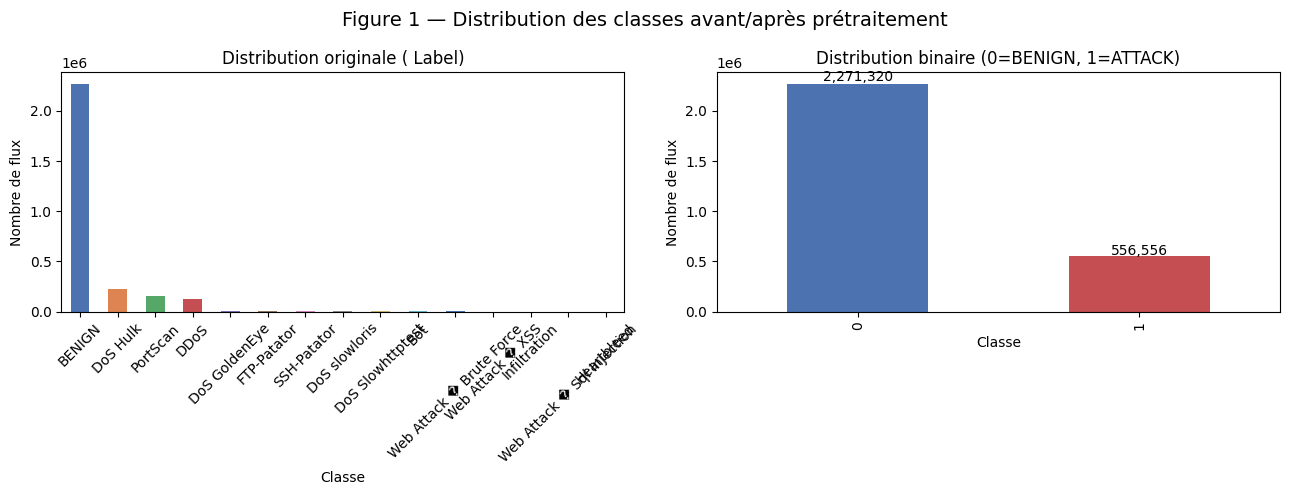

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

df[LABEL_COL].value_counts().plot(kind='bar', ax=axes[0],
                                   color=sns.color_palette('deep'))
axes[0].set_title(f'Distribution originale ({LABEL_COL})')
axes[0].set_xlabel('Classe'); axes[0].set_ylabel('Nombre de flux')
axes[0].tick_params(axis='x', rotation=45)

df['target'].value_counts().sort_index().plot(
    kind='bar', ax=axes[1], color=['#4C72B0', '#C44E52'])
axes[1].set_title('Distribution binaire (0=BENIGN, 1=ATTACK)')
axes[1].set_xlabel('Classe'); axes[1].set_ylabel('Nombre de flux')
for i, v in enumerate(df['target'].value_counts().sort_index().values):
    axes[1].text(i, v + v*0.01, f'{v:,}', ha='center', fontsize=10)

plt.suptitle('Figure 1 — Distribution des classes avant/après prétraitement',
             fontsize=14)
plt.tight_layout()
plt.savefig('fig01_distribution_classes.png', dpi=300)
plt.show()

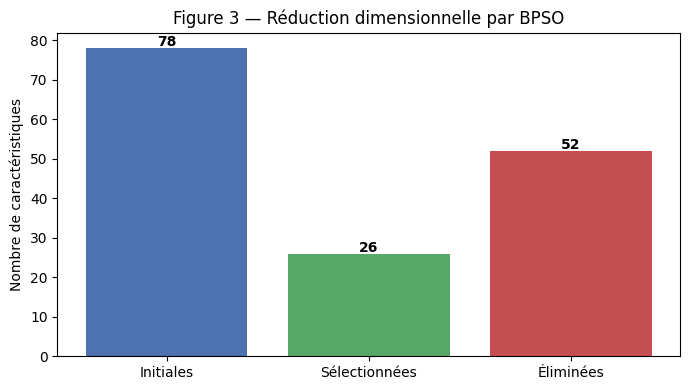

In [31]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(['Initiales','Sélectionnées','Éliminées'],
              [D, len(selected_features), D-len(selected_features)],
              color=['#4C72B0','#55A868','#C44E52'])
for bar, v in zip(bars, [D, len(selected_features), D-len(selected_features)]):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            str(v), ha='center', fontweight='bold')
ax.set_title('Figure 3 — Réduction dimensionnelle par BPSO')
ax.set_ylabel('Nombre de caractéristiques')
plt.tight_layout()
plt.savefig('fig03_reduction_dimensionnelle.png', dpi=300)
plt.show()

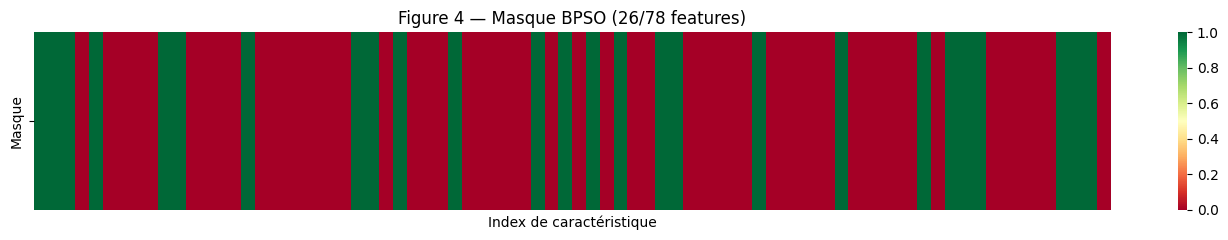

In [32]:
# ============================================================
# Figure 4 — Heatmap du masque optimal
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

if 'best_position' not in globals():
    raise RuntimeError("Exécutez la cellule 27.")

fig, ax = plt.subplots(figsize=(14, 2.5))
sns.heatmap(best_position.reshape(1, -1), cmap='RdYlGn',
            cbar=True, xticklabels=False, yticklabels=['Masque'], ax=ax)
ax.set_title(f'Figure 4 — Masque BPSO ({len(selected_features)}/{D} features)',
             fontsize=12)
ax.set_xlabel('Index de caractéristique')
plt.tight_layout()
plt.savefig('fig04_masque_binaire.png', dpi=300)
plt.show()

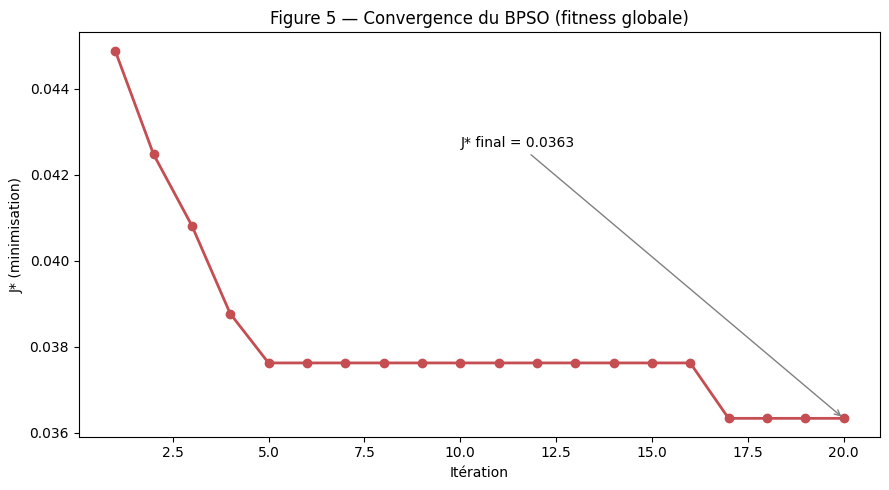

In [33]:
fig, ax = plt.subplots(figsize=(9, 5))
it = range(1, N_ITERATIONS + 1)
ax.plot(it, convergence_curve, 'o-', color='#C44E52', linewidth=2, markersize=6)
ax.set_title('Figure 5 — Convergence du BPSO (fitness globale)')
ax.set_xlabel('Itération'); ax.set_ylabel('J* (minimisation)')
ax.annotate(f'J* final = {convergence_curve[-1]:.4f}',
            xy=(N_ITERATIONS, convergence_curve[-1]),
            xytext=(N_ITERATIONS*0.5, convergence_curve[0]*0.95),
            arrowprops=dict(arrowstyle='->', color='gray'))
plt.tight_layout()
plt.savefig('fig05_convergence_bpso.png', dpi=300)
plt.show()

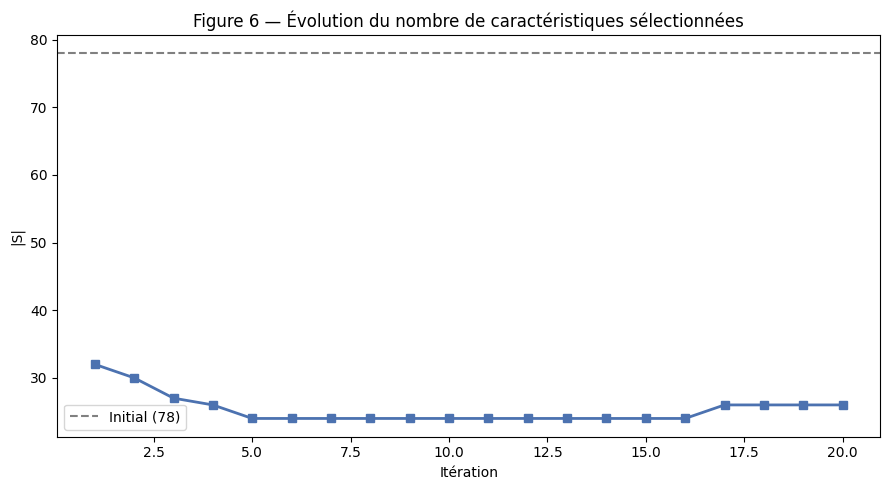

In [34]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(it, n_features_curve, 's-', color='#4C72B0', linewidth=2, markersize=6)
ax.axhline(D, color='gray', linestyle='--', label=f'Initial ({D})')
ax.set_title('Figure 6 — Évolution du nombre de caractéristiques sélectionnées')
ax.set_xlabel('Itération'); ax.set_ylabel('|S|')
ax.legend()
plt.tight_layout()
plt.savefig('fig06_evolution_nb_features.png', dpi=300)
plt.show()

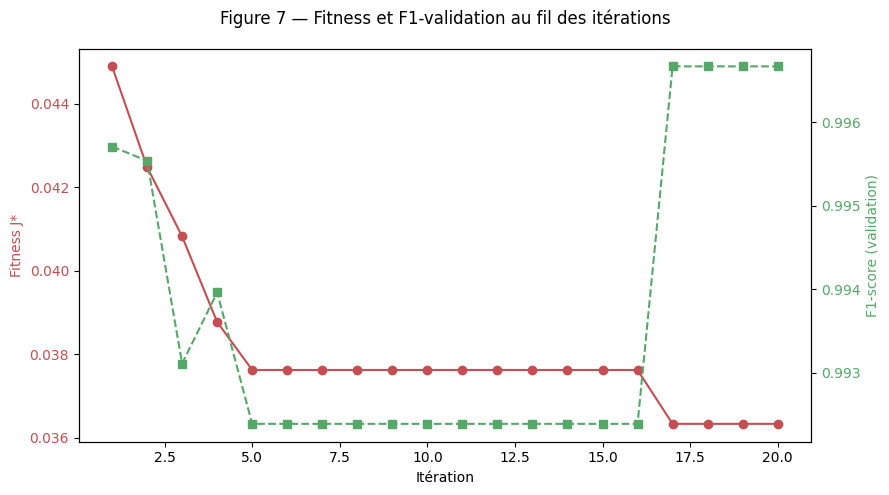

In [35]:
fig, ax1 = plt.subplots(figsize=(9, 5))
c1, c2 = '#C44E52', '#55A868'
ax1.plot(it, convergence_curve, 'o-', color=c1, label='Fitness J*')
ax1.set_xlabel('Itération')
ax1.set_ylabel('Fitness J*', color=c1)
ax1.tick_params(axis='y', labelcolor=c1)

ax2 = ax1.twinx()
ax2.plot(it, f1_val_curve, 's--', color=c2, label='F1 validation')
ax2.set_ylabel('F1-score (validation)', color=c2)
ax2.tick_params(axis='y', labelcolor=c2)

plt.suptitle('Figure 7 — Fitness et F1-validation au fil des itérations')
plt.tight_layout()
plt.savefig('fig07_fitness_f1.png', dpi=300)
plt.show()

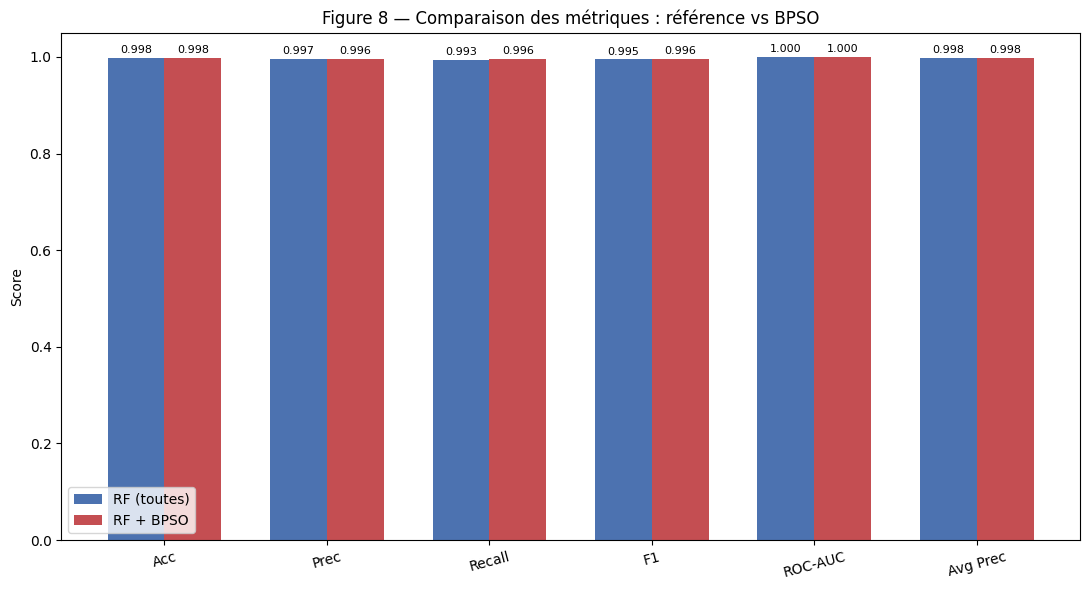

In [37]:
import numpy as np
import matplotlib.pyplot as plt

metriques_plot = ['accuracy','precision','recall','f1','roc_auc','average_precision']
labels_plot    = ['Acc','Prec','Recall','F1','ROC-AUC','Avg Prec']
x = np.arange(len(metriques_plot)); w = 0.35

fig, ax = plt.subplots(figsize=(11, 6))
b1 = ax.bar(x - w/2, [metrics_full[m] for m in metriques_plot], w,
            label='RF (toutes)', color='#4C72B0')
b2 = ax.bar(x + w/2, [metrics_bpso[m] for m in metriques_plot], w,
            label='RF + BPSO', color='#C44E52')
ax.set_xticks(x); ax.set_xticklabels(labels_plot, rotation=15)
ax.set_ylim(0, 1.05); ax.set_ylabel('Score')
ax.set_title('Figure 8 — Comparaison des métriques : référence vs BPSO')
ax.legend()
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.01,
                f'{b.get_height():.3f}', ha='center', fontsize=8)
plt.tight_layout()
plt.savefig('fig08_comparaison_metriques.png', dpi=300)
plt.show()

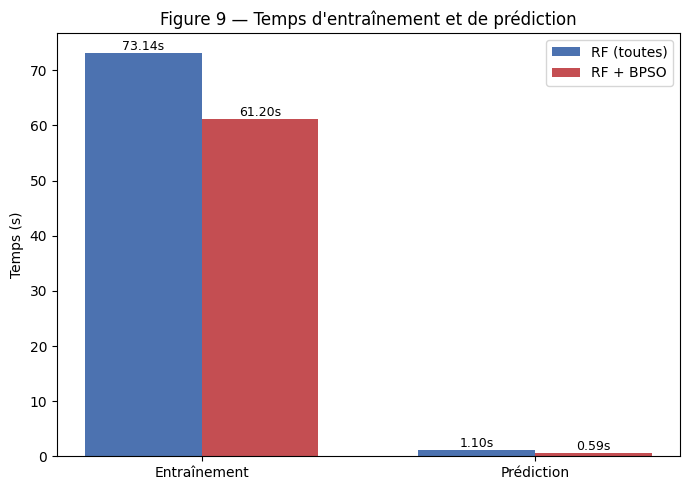

In [38]:
fig, ax = plt.subplots(figsize=(7, 5))
labels = ['Entraînement','Prédiction']
v_full = [train_time_full, pred_time_full]
v_bpso = [train_time_bpso, pred_time_bpso]
x = np.arange(2); w = 0.35
ax.bar(x - w/2, v_full, w, label='RF (toutes)', color='#4C72B0')
ax.bar(x + w/2, v_bpso, w, label='RF + BPSO', color='#C44E52')
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel('Temps (s)')
ax.set_title('Figure 9 — Temps d\'entraînement et de prédiction')
ax.legend()
for i, (a, b) in enumerate(zip(v_full, v_bpso)):
    ax.text(i-w/2, a, f'{a:.2f}s', ha='center', va='bottom', fontsize=9)
    ax.text(i+w/2, b, f'{b:.2f}s', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig('fig09_comparaison_temps.png', dpi=300)
plt.show()

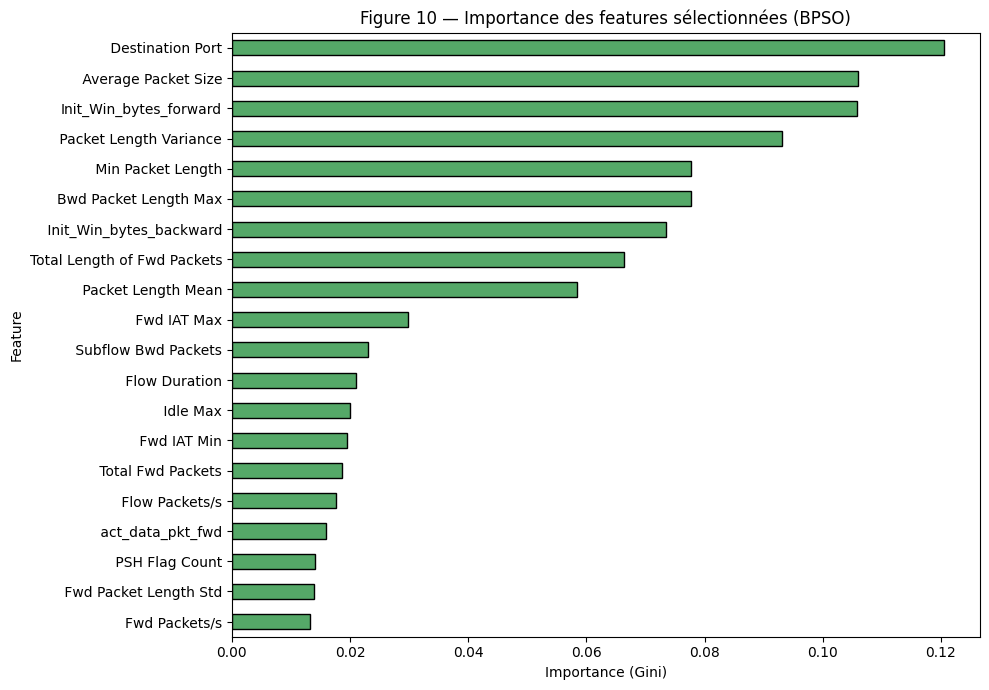

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

importances_bpso = pd.Series(
    rf_bpso.feature_importances_, index=selected_features
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
importances_bpso.head(20)[::-1].plot(kind='barh', ax=ax,
                                      color='#55A868', edgecolor='black')
ax.set_title('Figure 10 — Importance des features sélectionnées (BPSO)')
ax.set_xlabel('Importance (Gini)'); ax.set_ylabel('Feature')
plt.tight_layout()
plt.savefig('fig10_importances_bpso.png', dpi=300)
plt.show()

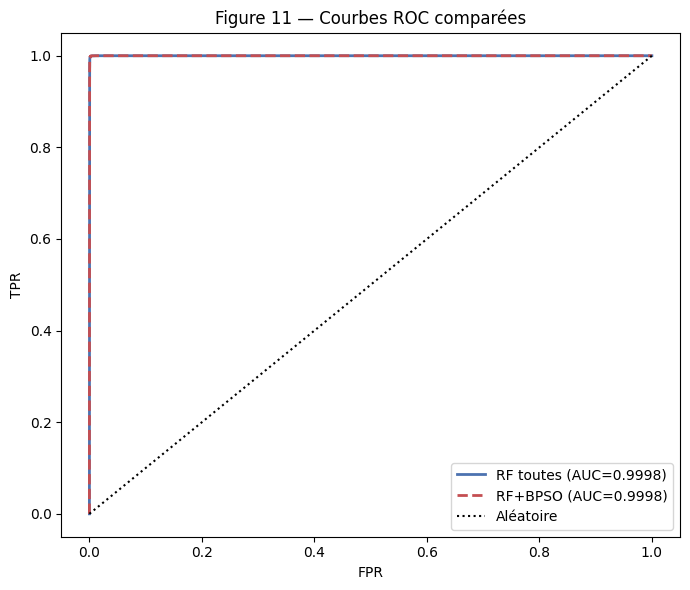

In [40]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr_f, tpr_f, _ = roc_curve(y_test, y_proba_full)
fpr_b, tpr_b, _ = roc_curve(y_test, y_proba_bpso)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr_f, tpr_f, color='#4C72B0', lw=2,
        label=f'RF toutes (AUC={metrics_full["roc_auc"]:.4f})')
ax.plot(fpr_b, tpr_b, color='#C44E52', lw=2, ls='--',
        label=f'RF+BPSO (AUC={metrics_bpso["roc_auc"]:.4f})')
ax.plot([0,1],[0,1],'k:', label='Aléatoire')
ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
ax.set_title('Figure 11 — Courbes ROC comparées')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('fig11_courbes_roc.png', dpi=300)
plt.show()

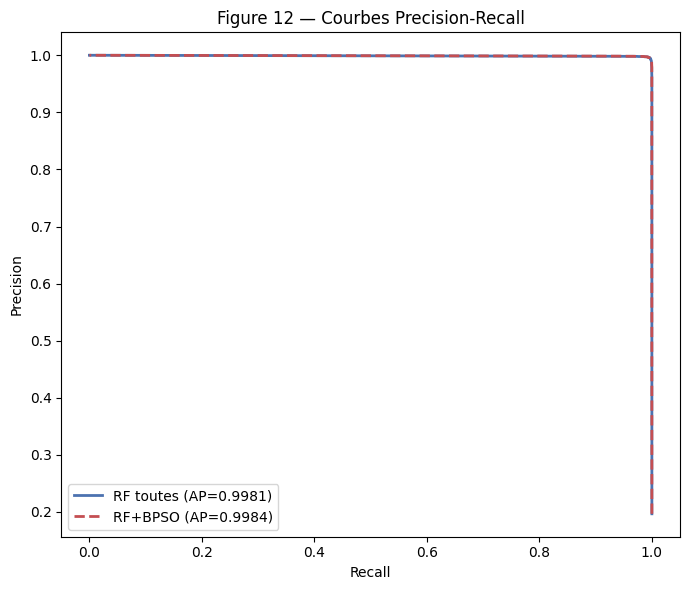

In [41]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

p_f, r_f, _ = precision_recall_curve(y_test, y_proba_full)
p_b, r_b, _ = precision_recall_curve(y_test, y_proba_bpso)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(r_f, p_f, color='#4C72B0', lw=2,
        label=f'RF toutes (AP={metrics_full["average_precision"]:.4f})')
ax.plot(r_b, p_b, color='#C44E52', lw=2, ls='--',
        label=f'RF+BPSO (AP={metrics_bpso["average_precision"]:.4f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Figure 12 — Courbes Precision-Recall')
ax.legend()
plt.tight_layout()
plt.savefig('fig12_courbes_pr.png', dpi=300)
plt.show()

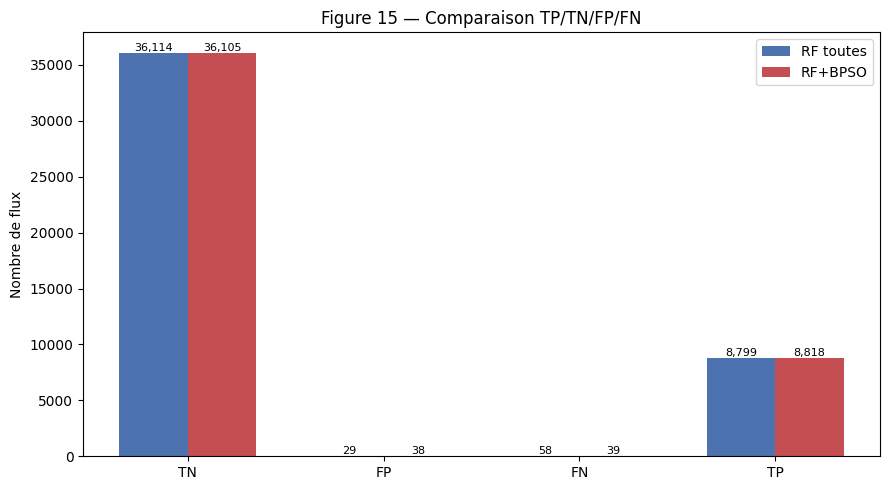

In [42]:
import numpy as np
import matplotlib.pyplot as plt

vals_full = [tn_full, fp_full, fn_full, tp_full]
vals_bpso = [tn_bpso, fp_bpso, fn_bpso, tp_bpso]
labels_cm = ['TN','FP','FN','TP']
x = np.arange(4); w = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - w/2, vals_full, w, label='RF toutes', color='#4C72B0')
ax.bar(x + w/2, vals_bpso, w, label='RF+BPSO', color='#C44E52')
ax.set_xticks(x); ax.set_xticklabels(labels_cm)
ax.set_ylabel('Nombre de flux')
ax.set_title('Figure 15 — Comparaison TP/TN/FP/FN')
ax.legend()
for i, (a, b) in enumerate(zip(vals_full, vals_bpso)):
    ax.text(i-w/2, a, f'{a:,}', ha='center', va='bottom', fontsize=8)
    ax.text(i+w/2, b, f'{b:,}', ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.savefig('fig15_comparaison_tp_tn_fp_fn.png', dpi=300)
plt.show()

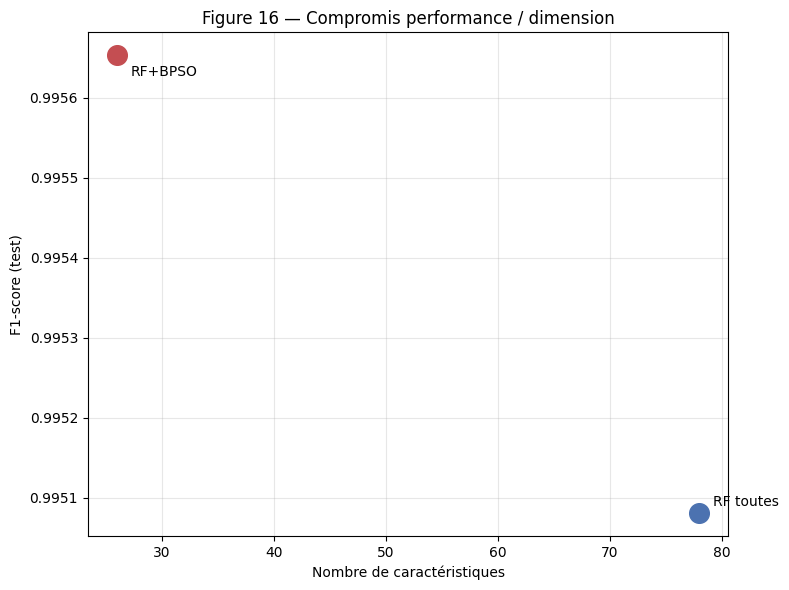

In [43]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(D, metrics_full['f1'], s=200, c='#4C72B0', label='RF toutes', zorder=5)
ax.scatter(len(selected_features), metrics_bpso['f1'], s=200, c='#C44E52',
           label='RF+BPSO', zorder=5)
ax.annotate('RF toutes', (D, metrics_full['f1']),
            xytext=(10, 5), textcoords='offset points')
ax.annotate('RF+BPSO', (len(selected_features), metrics_bpso['f1']),
            xytext=(10, -15), textcoords='offset points')
ax.set_xlabel('Nombre de caractéristiques')
ax.set_ylabel('F1-score (test)')
ax.set_title('Figure 16 — Compromis performance / dimension')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig16_compromis_performance_dimension.png', dpi=300)
plt.show()

In [44]:
import pandas as pd

synthese = pd.DataFrame({
    'Indicateur': [
        'Caractéristiques initiales','Caractéristiques sélectionnées',
        'Taux de réduction (%)','F1 (référence)','F1 (BPSO)','Δ F1',
        'Recall ATTACK (référence)','Recall ATTACK (BPSO)','Δ Recall ATTACK',
        'ROC-AUC (référence)','ROC-AUC (BPSO)',
        'Temps entraînement référence (s)','Temps entraînement BPSO (s)',
        'Gain temps entraînement (s)',
        'Durée totale BPSO (s)','Évaluations fitness'
    ],
    'Valeur': [
        D, len(selected_features), round(reduction_pct, 2),
        round(metrics_full['f1'], 4), round(metrics_bpso['f1'], 4),
        round(delta_f1, 4),
        round(metrics_full['recall'], 4), round(metrics_bpso['recall'], 4),
        round(delta_recall, 4),
        round(metrics_full['roc_auc'], 4), round(metrics_bpso['roc_auc'], 4),
        round(train_time_full, 2), round(train_time_bpso, 2),
        round(gain_t_train, 2),
        round(temps_total_pso, 1), n_evaluations_total
    ]
})
display(synthese)
synthese.to_csv('synthese_scientifique.csv', index=False)
print('✅ Sauvegardé dans synthese_scientifique.csv')

,Indicateur,Valeur
0,Caractéristiques initiales,78.0000
1,Caractéristiques sélectionnées,26.0000
2,Taux de réduction (%),66.6700
3,F1 (référence),0.9951
4,F1 (BPSO),0.9957
5,Δ F1,0.0006
6,Recall ATTACK (référence),0.9935
7,Recall ATTACK (BPSO),0.9956
8,Δ Recall ATTACK,0.0021
9,ROC-AUC (référence),0.9998


✅ Sauvegardé dans synthese_scientifique.csv


In [45]:
print('=== Interprétation scientifique ===\n')

if delta_f1 > 0.005:
    print(f'1. F1 augmente de {delta_f1:+.4f} avec BPSO. '
          'L\'élimination de features redondantes/bruitées a pu aider la généralisation.')
elif delta_f1 < -0.005:
    print(f'1. F1 diminue de {delta_f1:+.4f} avec BPSO. '
          'La réduction dimensionnelle a un coût en performance.')
else:
    print('1. F1 stable (|Δ| ≤ 0,005). Aucune dégradation détectée.')

if delta_recall >= -0.01:
    print(f'2. Recall ATTACK maintenu (Δ={delta_recall:+.4f}). '
          'Détection des intrusions préservée.')
else:
    print(f'2. Recall ATTACK dégradé (Δ={delta_recall:+.4f}). '
          'Risque accru de faux négatifs en production.')

print(f'3. {D-len(selected_features)} features éliminées ({reduction_pct:.1f} %).')

if gain_t_train > 0:
    print(f'4. Temps d\'entraînement réduit de {gain_t_train:.2f} s '
          f'({100*gain_t_train/train_time_full:.1f} %).')
else:
    print(f'4. Pas de gain net sur l\'entraînement ({gain_t_train:+.2f} s). '
          'Le coût du BPSO ({temps_total_pso:.0f} s) n\'est pas inclus.')

print(f'5. Compromis : réduction {reduction_pct:.1f} % vs Δ F1 {delta_f1:+.4f}.')
print('   Décision à arbitrer selon les contraintes opérationnelles du NIDS.')

=== Interprétation scientifique ===

1. F1 stable (|Δ| ≤ 0,005). Aucune dégradation détectée.
2. Recall ATTACK maintenu (Δ=+0.0021). Détection des intrusions préservée.
3. 52 features éliminées (66.7 %).
4. Temps d'entraînement réduit de 11.94 s (16.3 %).
5. Compromis : réduction 66.7 % vs Δ F1 +0.0006.
   Décision à arbitrer selon les contraintes opérationnelles du NIDS.


## Limites expérimentales

1. **Échantillonnage** : si `TAILLE_ECHANTILLON` < dataset complet, les résultats ne représentent qu'un sous-ensemble stratifié. Généralisation au dataset entier à vérifier.

2. **Coût du BPSO** : la durée totale du BPSO (`temps_total_pso`) n'est **pas incluse** dans le temps d'entraînement du modèle final. Une évaluation de bout en bout doit l'intégrer.

3. **Généralisation externe** : test issu du même dataset. Une validation sur UNSW-NB15 ou CIC-IDS2018 serait nécessaire pour conclure à une vraie robustesse.

4. **Déséquilibre** : `class_weight='balanced_subsample'` atténue mais n'élimine pas le déséquilibre BENIGN/ATTACK. Optimisation du seuil de décision envisageable.

5. **Risque de fuite** : `Destination Port` pourrait être corrélé à des types d'attaques. Une analyse d'ablation par feature serait souhaitable.

6. **Stochasticité du BPSO** : une seule exécution ne prouve pas la robustesse du masque. Répétitions multi-seeds nécessaires.

## Conclusion

Cette expérimentation a appliqué le Binary PSO pour sélectionner un sous-ensemble de caractéristiques du CIC-IDS2017 en vue d'une détection binaire d'intrusions.

**Résultats mesurés** (dynamiques — voir cellule 41 pour les valeurs exactes) :
- Réduction dimensionnelle : de `D` à `len(selected_features)` features.
- Variation du F1-score : `delta_f1` (test indépendant).
- Variation du rappel ATTACK : `delta_recall`.
- Gain de temps d'entraînement : `gain_t_train`.

**Interprétation** : le BPSO réduit la dimensionnalité de manière significative. L'effet sur la performance varie — la décision d'adopter cette approche dépend du compromis entre coût de calcul, parcimonie et sensibilité de détection.

**Perspectives** : multi-seeds, itérations/particules augmentées, classificateurs alternatifs (XGBoost, SVM), validation externe (UNSW-NB15).

In [46]:
from pathlib import Path

# 1. Métriques comparatives
comparaison.to_csv('resultats_comparaison_metriques.csv', index=False)

# 2. Features sélectionnées
import pandas as pd, numpy as np
pd.DataFrame({
    'feature': selected_features,
    'index_original': selected_indices
}).to_csv('resultats_features_selectionnees.csv', index=False)

# 3. Historique convergence
df_historique.to_csv('resultats_historique_convergence.csv', index=False)

# 4. Importances
importances_full.to_csv('resultats_importances_reference.csv', header=['importance'])
importances_bpso.to_csv('resultats_importances_bpso.csv', header=['importance'])

# 5. Matrices de confusion
pd.DataFrame({
    'modele': ['reference']*4 + ['bpso']*4,
    'composante': ['TN','FP','FN','TP']*2,
    'valeur': [tn_full, fp_full, fn_full, tp_full,
               tn_bpso, fp_bpso, fn_bpso, tp_bpso]
}).to_csv('resultats_matrice_confusion.csv', index=False)

print('Fichiers exportés :')
for f in sorted(Path('.').glob('resultats_*.csv')):
    print(' -', f)

Fichiers exportés :
 - resultats_comparaison_metriques.csv
 - resultats_features_selectionnees.csv
 - resultats_historique_convergence.csv
 - resultats_importances_bpso.csv
 - resultats_importances_reference.csv
 - resultats_matrice_confusion.csv


In [47]:
import shutil, zipfile
from pathlib import Path

DOSSIER = Path('resultats_experience_bpso')
DOSSIER.mkdir(exist_ok=True)

for pattern in ['fig*.png', 'resultats_*.csv',
                'comparaison_metriques.csv', 'synthese_scientifique.csv',
                'features_selectionnees_bpso.csv']:
    for f in Path('.').glob(pattern):
        dest = DOSSIER / f.name
        if not dest.exists():
            shutil.copy(f, dest)

archive = 'resultats_experience_bpso.zip'
with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as zf:
    for f in DOSSIER.rglob('*'):
        if f.is_file():
            zf.write(f, f.relative_to(DOSSIER.parent))

print(f'Archive créée : {archive}')
print('Contenu :')
for f in sorted(DOSSIER.iterdir()):
    print(' -', f.name)

Archive créée : resultats_experience_bpso.zip
Contenu :
 - comparaison_metriques.csv
 - features_selectionnees_bpso.csv
 - fig01_distribution_classes.png
 - fig03_reduction_dimensionnelle.png
 - fig04_masque_binaire.png
 - fig05_convergence_bpso.png
 - fig06_evolution_nb_features.png
 - fig07_fitness_f1.png
 - fig08_comparaison_metriques.png
 - fig09_comparaison_temps.png
 - fig10_importances_bpso.png
 - fig11_courbes_roc.png
 - fig12_courbes_pr.png
 - fig13_confusion_reference.png
 - fig14_confusion_bpso.png
 - fig15_comparaison_tp_tn_fp_fn.png
 - fig16_compromis_performance_dimension.png
 - fig_top20_importances_full.png
 - resultats_comparaison_metriques.csv
 - resultats_features_selectionnees.csv
 - resultats_historique_convergence.csv
 - resultats_importances_bpso.csv
 - resultats_importances_reference.csv
 - resultats_matrice_confusion.csv
 - synthese_scientifique.csv


In [48]:
print('=' * 70)
print('RÉSUMÉ FINAL DE L\'EXPÉRIENCE')
print('=' * 70)

print('\n--- PARAMÈTRES ---')
print(f'Dataset           : muzom/CIC-IDS2017')
print(f'Échantillon       : {len(X_sample):,} lignes')
print(f'Seed              : {SEED}')
print(f'Particules BPSO   : {N_PARTICULES}')
print(f'Itérations BPSO   : {N_ITERATIONS}')
print(f'Fitness           : J = {ALPHA_FITNESS}·(1-F1) + {1-ALPHA_FITNESS:.2f}·(|S|/D)')

print('\n--- DIMENSIONS ---')
print(f'Initiales          : {D}')
print(f'Sélectionnées      : {len(selected_features)}')
print(f'Réduction          : {reduction_pct:.2f} %')

print('\n--- PERFORMANCES (TEST) ---')
print(f'{"Métrique":20s} {"Réf":>10s} {"BPSO":>10s} {"Δ":>10s}')
for m, lab in [('accuracy','Accuracy'),('precision','Precision'),
               ('recall','Recall'),('f1','F1-score'),
               ('roc_auc','ROC-AUC'),('average_precision','Avg Prec')]:
    print(f'{lab:20s} {metrics_full[m]:10.4f} {metrics_bpso[m]:10.4f} '
          f'{metrics_bpso[m]-metrics_full[m]:+10.4f}')

print('\n--- TEMPS ---')
print(f'Entraînement réf   : {train_time_full:.2f} s')
print(f'Entraînement BPSO  : {train_time_bpso:.2f} s')
print(f'Prédiction réf     : {pred_time_full:.2f} s')
print(f'Prédiction BPSO    : {pred_time_bpso:.2f} s')
print(f'BPSO total         : {temps_total_pso:.1f} s')
print(f'Évaluations        : {n_evaluations_total}')

print('\n--- FICHIERS ---')
print(f'Archive : resultats_experience_bpso.zip')
print(f'Dossier : {DOSSIER.resolve()}')

print('\n' + '=' * 70)
print('Expérience terminée.')
print('=' * 70)

RÉSUMÉ FINAL DE L'EXPÉRIENCE

--- PARAMÈTRES ---
Dataset           : muzom/CIC-IDS2017
Échantillon       : 300,000 lignes
Seed              : 2026
Particules BPSO   : 10
Itérations BPSO   : 20
Fitness           : J = 0.9·(1-F1) + 0.10·(|S|/D)

--- DIMENSIONS ---
Initiales          : 78
Sélectionnées      : 26
Réduction          : 66.67 %

--- PERFORMANCES (TEST) ---
Métrique                    Réf       BPSO          Δ
Accuracy                 0.9981     0.9983    +0.0002
Precision                0.9967     0.9957    -0.0010
Recall                   0.9935     0.9956    +0.0021
F1-score                 0.9951     0.9957    +0.0006
ROC-AUC                  0.9998     0.9998    +0.0000
Avg Prec                 0.9981     0.9984    +0.0002

--- TEMPS ---
Entraînement réf   : 73.14 s
Entraînement BPSO  : 61.20 s
Prédiction réf     : 1.10 s
Prédiction BPSO    : 0.59 s
BPSO total         : 4348.3 s
Évaluations        : 210

--- FICHIERS ---
Archive : resultats_experience_bpso.zip
Dossier : /

In [49]:

import glob
from google.colab import files

zip_files = glob.glob(
    '/content/**/resultats_experience_bpso.zip',
    recursive=True
)

if zip_files:
    print("Fichier trouvé :", zip_files[0])
    files.download(zip_files[0])
else:
    print("Fichier ZIP introuvable dans /content")


Fichier trouvé : /content/resultats_experience_bpso.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>